**Importar librerias**

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import datetime
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras import optimizers
import tensorflow_datasets as tfds
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
import seaborn as sns
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.optimizers import Adagrad
from tensorflow.keras.optimizers import Lion
from tensorflow.keras.optimizers import RMSprop
from collections import Counter
import os
import json
from tensorflow.keras import models
from tensorflow.keras import metrics
from collections import Counter
from sklearn.metrics import precision_score, accuracy_score,classification_report,confusion_matrix


In [ ]:
#Constantes
markersize = 8
linewidth = 2

color_train = '#1f77b4'
color_val = '#ff7f0e'
plt.style.use('ggplot')

nombres=["healthy", "angular_leaf_spot", "bean_rust"]

**Cargar base de datos para el analisis**

In [ ]:
data=tfds.load('beans', split='all', as_supervised=True)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/3 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/beans/incomplete.SGUVQ0_0.1.0/beans-train.tfrecord*...:   0%|          | 0…

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/beans/incomplete.SGUVQ0_0.1.0/beans-validation.tfrecord*...:   0%|        …

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/beans/incomplete.SGUVQ0_0.1.0/beans-test.tfrecord*...:   0%|          | 0/…

Dataset beans downloaded and prepared to /root/tensorflow_datasets/beans/0.1.0. Subsequent calls will reuse this data.


**Visualizar las imagenes**

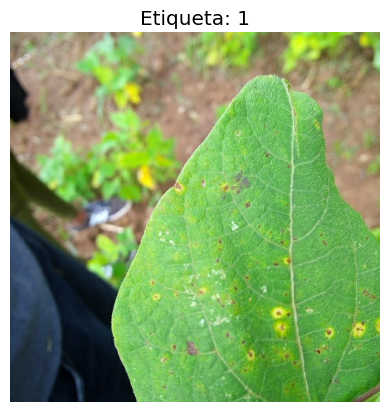

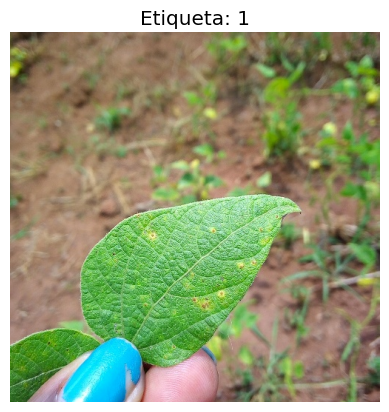

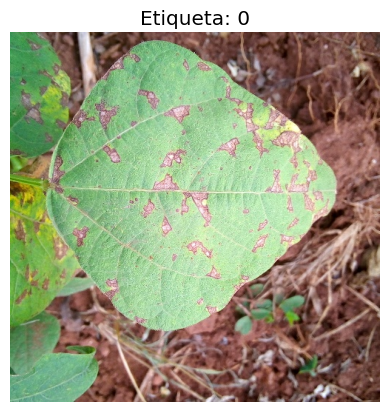

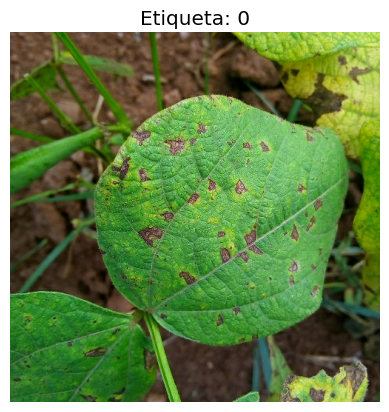

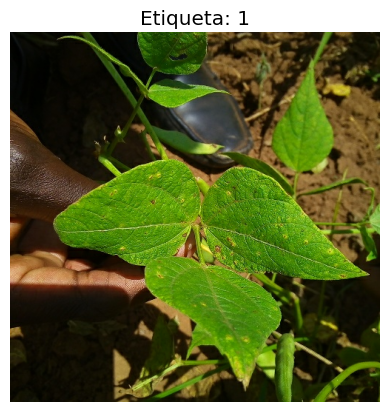

...

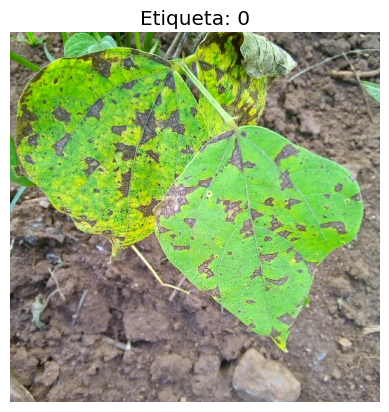

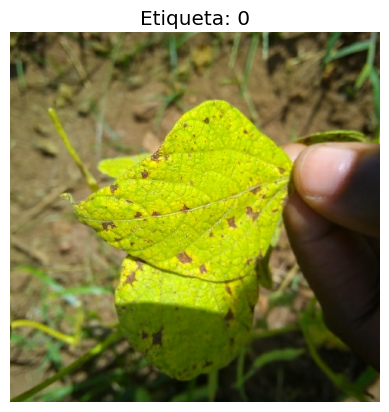

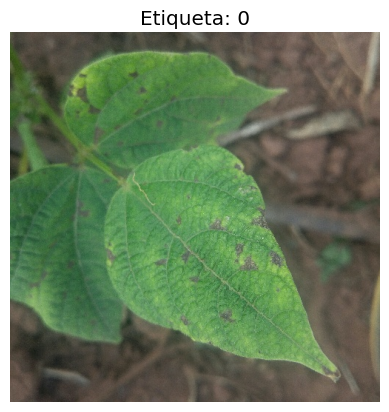

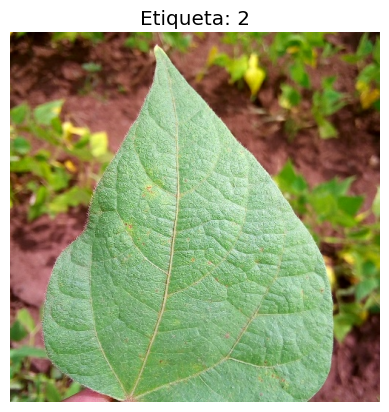

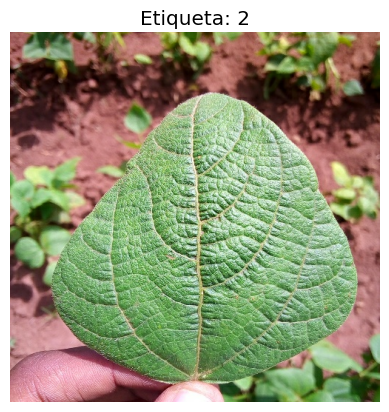

In [ ]:
import matplotlib.pyplot as plt

for image, label in data.take(15):
    plt.imshow(image)
    plt.title(f"Etiqueta: {label.numpy()}")
    plt.axis('off')
    plt.show()


In [ ]:
#Se separan los datos en train,validation y test,de las 1295 1035 son train,131 validacion y 129 de testeo
train_data, val_data, test_data = tfds.load(
    'beans',
    split=['train[:80%]+validation[:80%]+test[:80%]',
        'train[80%:90%]+validation[80%:90%]+test[80%:90%]',
        'train[90%:]+validation[90%:]+test[90%:]'
    ],
    as_supervised=True
)

# Convertir datos a arrays
def tfds_to_numpy(dataset):
    X, y = [], []
    for image, label in tfds.as_numpy(dataset):
        X.append(image)
        y.append(label)
    return np.array(X), np.array(y)

X_train, y_train = tfds_to_numpy(train_data)
X_val, y_val = tfds_to_numpy(val_data)
X_test, y_test = tfds_to_numpy(test_data)

# Ajustar forma de etiquetas
y_train = y_train.reshape(-1,)
y_val = y_val.reshape(-1,)
y_test = y_test.reshape(-1,)

#Ver información de los datos
print("X_train:", X_train.shape)#1035 imagenes de entrenamiento,de 500x500
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)#Validacion 131
print("y_val:", y_val.shape)
print("X_test:", X_test.shape)#Testeo 129
print("y_test:", y_test.shape)

X_train: (1035, 500, 500, 3)
y_train: (1035,)
X_val: (131, 500, 500, 3)
y_val: (131,)
X_test: (129, 500, 500, 3)
y_test: (129,)


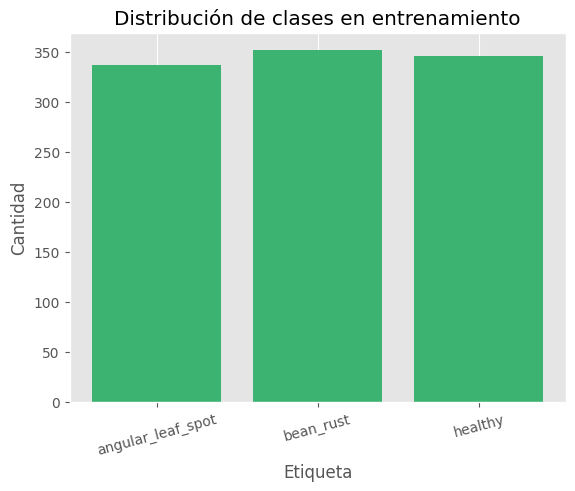

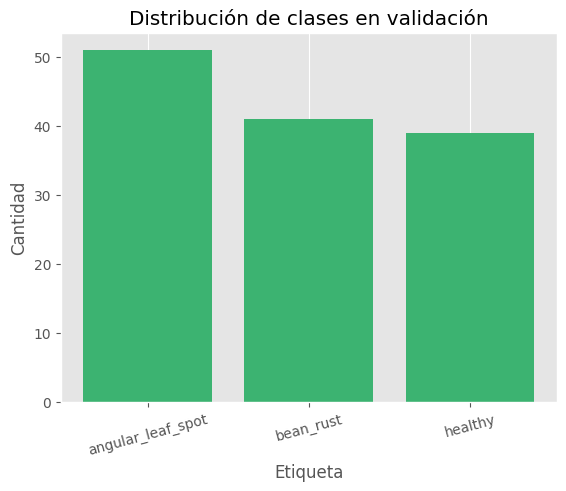

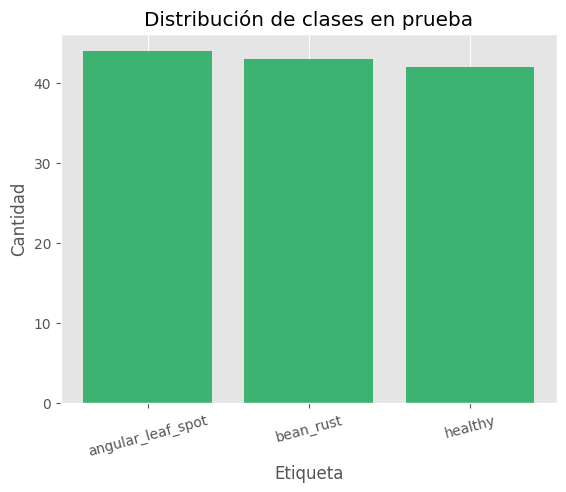

In [ ]:
#Analisis descriptivo de los datos
import matplotlib.pyplot as plt
class_names = ['angular_leaf_spot', 'bean_rust', 'healthy']

def graficar_clases(dataset, nombre):
    contador = Counter()
    for _, label in dataset:
        contador[int(label.numpy())] += 1
    valores = [contador[i] for i in range(len(class_names))]
    plt.bar(class_names, valores, color='mediumseagreen')
    plt.title(f"Distribución de clases en {nombre}")
    plt.xlabel("Etiqueta")
    plt.ylabel("Cantidad")
    plt.xticks(rotation=15)
    plt.grid(axis='y')
    plt.show()

graficar_clases(train_data, "entrenamiento")
graficar_clases(val_data, "validación")
graficar_clases(test_data, "prueba")


# Funciones importantes

In [ ]:

def preprocess_and_augment(image, label, training=True):

    # Normalizar a 0 y 1
    image = tf.cast(image, tf.float32) / 255.0

    # Resize to ResNet50 input
    image = tf.image.resize(image, (128, 128))

    if training:
        # Random horizontal flip
        image = tf.image.random_flip_left_right(image)
        #image = tf.image.random_brightness(image, max_delta=0.1)  # + variación
       # image = tf.image.random_contrast(image, 0.9, 1.1)         # + contraste
        # Random rotation (0, 90, 180, 270 grados)
        k = tf.random.uniform(shape=[], minval=0, maxval=4, dtype=tf.int32)
        image = tf.image.rot90(image, k)
        # Random zoom via random crop
        crop_size = tf.random.uniform([], int(0.8*128), 128, dtype=tf.int32)
        image = tf.image.random_crop(image, size=[crop_size, crop_size, 3])
        image = tf.image.resize(image, (128, 128))

    return image, label

batch_size = 64

# Training dataset with augmentation

train_ds_aug = tf.data.Dataset.from_tensor_slices((X_train, y_train)) \
    .map(lambda x, y: preprocess_and_augment(x, y, training=True), num_parallel_calls=tf.data.AUTOTUNE) \
    .shuffle(1000) \
    .batch(batch_size) \
    .prefetch(tf.data.AUTOTUNE)

# Dataset de validación sin aumentación
val_ds_pre = tf.data.Dataset.from_tensor_slices((X_val, y_val)) \
    .map(lambda x, y: preprocess_and_augment(x, y, training=False), num_parallel_calls=tf.data.AUTOTUNE) \
    .batch(batch_size) \
    .prefetch(tf.data.AUTOTUNE)

# Dataset de prueba sin aumentación
test_ds_pre = tf.data.Dataset.from_tensor_slices((X_test, y_test)) \
    .map(lambda x, y: preprocess_and_augment(x, y, training=False), num_parallel_calls=tf.data.AUTOTUNE) \
    .batch(batch_size) \
    .prefetch(tf.data.AUTOTUNE)

# Dataset de entrenamiento SIN augmentación, solo para métricas
train_ds_for_metrics = tf.data.Dataset.from_tensor_slices((X_train, y_train)) \
    .map(lambda x, y: preprocess_and_augment(x, y, training=False), num_parallel_calls=tf.data.AUTOTUNE) \
    .batch(batch_size) \
    .prefetch(tf.data.AUTOTUNE)

In [ ]:
for images, labels in train_ds_aug.take(1):
    print("Shape de un batch:", images.shape)
    print("Rango de valores:", tf.reduce_min(images).numpy(), "a", tf.reduce_max(images).numpy())


Shape de un batch: (64, 128, 128, 3)
Rango de valores: 0.0 a 1.0


####Precisión por epoch

In [ ]:
#Esto guarda la precisión por epoch
class PrecisionPerEpoch(tf.keras.callbacks.Callback):#Hereda de tf.keras.callbacks.Callback
    def __init__(self, train_ds, val_ds):#Iniciador
        super().__init__()
        self.train_ds = train_ds #Guarda la base de entenaamiento
        self.val_ds = val_ds #Guarda la base de validación
        self.train_precisions = [] #Crea una lista vacia para guardar la precisión por epoch para el train
        self.val_precisions = [] #Crea una lista vacia para guardar la precisión por epoch para la validación


    def on_epoch_end(self, epoch, logs=None):#Este método se ejecuta cuando termina una epoch
        # Precision training
        y_true_train = np.concatenate([y for _, y in self.train_ds], axis=0)# Extrae todas las etiquetas reales "y" y las une en vector
        y_pred_train = np.argmax(self.model.predict(self.train_ds, verbose=0), axis=1)#Usa el modelo actual para predecir sobre el conjunto de entrenamiento,predict() devuelve probabilidades([0.1, 0.7, 0.2]) y
        # np.argmax(..., axis=1) toma el índice de la clase con mayor probabilidad (el número de clase predicha).
        precision_train = precision_score(y_true_train, y_pred_train, average='macro')# Precisión promedio por clase precisión=(precision1+precision2+precision3)/3 , esto se usa porque las clases están balanceadas
        self.train_precisions.append(precision_train)#Guarda el valor en train_precisions

        # Precision validation,esto es para ver overfitting por si acaso se estanca la validación en precisión y la de entrenamiento sube.
        y_true_val = np.concatenate([y for _, y in self.val_ds], axis=0)
        y_pred_val = np.argmax(self.model.predict(self.val_ds, verbose=0), axis=1)
        precision_val = precision_score(y_true_val, y_pred_val, average='macro')
        self.val_precisions.append(precision_val)

        print(f"Epoch {epoch+1} - Precision Train: {precision_train:.4f} - Precision Val: {precision_val:.4f}")

####Función para valoración de rendimiento de precisión en testeo

In [ ]:
def precision_model(model, dataset):
    # Obtener etiquetas verdaderas del dataset
    y_true = np.concatenate([y for _, y in dataset], axis=0)

    # Obtener probas del modelo
    y_pred_prob = model.predict(dataset, verbose=0)

    # Convertir probabilidades a etiquetas predichas
    y_pred = np.argmax(y_pred_prob, axis=1)

    # Calcular precisión macro
    precision_macro = precision_score(y_true, y_pred, average='macro')

    return precision_macro

Función para calcular métrica accuracy y precision por clase

In [ ]:

def precision_accuracy_por_clase(model, dataset, nombres_clases = ["healthy", "angular_leaf_spot", "bean_rust"]
):
    # Obtener etiquetas verdaderas y predicciones
    y_true = np.concatenate([y for _, y in dataset], axis=0)
    y_pred = np.argmax(model.predict(dataset, verbose=0), axis=1)

    # Globales
    precision_macro = precision_score(y_true, y_pred, average='macro')
    accuracy_global = accuracy_score(y_true, y_pred)

    print(f"\nAccuracy global: {accuracy_global:.4f}")
    print(f"Precision macro global: {precision_macro:.4f}")

    # Por clase
    print("\n--- Métricas por clase ---")
    clases = np.unique(y_true)
    for c in clases:
        idx = np.where(y_true == c)
        acc_c = np.mean(y_pred[idx] == y_true[idx])
        prec_c = precision_score(y_true, y_pred, labels=[c], average='macro', zero_division=0)
        nombre = nombres_clases[c] if nombres_clases else str(c)
        print(f"Clase {nombre}: Accuracy = {acc_c:.4f} | Precision = {prec_c:.4f}")

Función para generar la matriz de confusión

In [ ]:

def plot_confusion_matrix(model, dataset, class_names=nombres, figsize=(6,5), cmap='Blues'):
    # Obtener predicciones
    y_true = np.concatenate([y for _, y in dataset], axis=0)
    y_pred = np.argmax(model.predict(dataset, verbose=0), axis=1)

    # Matriz de confusión
    cm = confusion_matrix(y_true, y_pred)

    # Mostrar la matriz
    plt.figure(figsize=figsize)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap,
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicción')
    plt.ylabel('Clase real')
    plt.title('Matriz de Confusión')
    plt.show()


#**Construir y entrenar modelos**

#MLP


**Optimizando el LR para MLP**

#En todo se usa 40 epochs y 64 batch_size

In [ ]:
#MLP con LR 0.0001

model1 = keras.models.Sequential()#Se crea el modelo secuencial,es decir se apila las capas una tras otra, el .add agrega una capa capa
model1.add(layers.Flatten(input_shape=(128, 128, 3)))#Esta capa covierte la imagen 128x128x3 en un vector de 1D, por eso al observar el el summary del modelo, son 49,152 porque son 128x128x3
model1.add(layers.Dense(512, activation='relu'))#Es una capa de 512 neuronas, la activación RELU es para introducir no linealidad,cada una de las neuronas recibe las 49152 entradas anteriores
model1.add(layers.Dense(256, activation='relu'))#Aqui es igual,solo que aquí se están aprendiendo patrones mas complejos
model1.add(layers.Dense(128, activation='relu'))#Aprender relaciones compactas
model1.add(layers.Dense(3, activation='softmax'))# Capa de salida

model1.compile(optimizer=optimizers.Adam(learning_rate=0.0001),
              loss='sparse_categorical_crossentropy', #El loss depende del Categorical Crossentropy,
               #está adaptada a etiquetas enteras (0, 1, 2), esto mide la
               #diferencia entre las probabilidades predichas por el modelo
               #y las etiquetas verdaderas,mientras mas cercano a 0 mejor.
              metrics=['accuracy']   )
model1.summary()
precision_callbackmlp1 = PrecisionPerEpoch(train_ds_for_metrics, val_ds_pre)

history1 = model1.fit( train_ds_aug, validation_data=val_ds_pre,  epochs=40,  batch_size=64,callbacks=[precision_callbackmlp1])#Aquí se entrena el modelo


/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 49152)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 512)            │    25,166,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,330,947 (96.63 MB)

 Trainable params: 25,330,947 (96.63 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.3588 - loss: 1.5114

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 1 - Precision Train: 0.3186 - Precision Val: 0.3595
17/17 ━━━━━━━━━━━━━━━━━━━━ 7s 248ms/step - accuracy: 0.3600 - loss: 1.5028 - val_accuracy: 0.4275 - val_loss: 1.1512
Epoch 2/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3979 - loss: 1.1235Epoch 2 - Precision Train: 0.5398 - Precision Val: 0.5311
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 160ms/step - accuracy: 0.3997 - loss: 1.1200 - val_accuracy: 0.4733 - val_loss: 1.0088
Epoch 3/40
13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4785 - loss: 1.0145Epoch 3 - Precision Train: 0.5423 - Precision Val: 0.5136
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 104ms/step - accuracy: 0.4788 - loss: 1.0135 - val_accuracy: 0.4809 - val_loss: 1.0934
Epoch 4/40
13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5050 - loss: 0.9856Epoch 4 - Precision Train: 0.5617 - Precision Val: 0.5321
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - accuracy: 0.5073 - loss: 0.9812 - val_accuracy: 0.4351 - val_loss: 1.0357
Epoch 5/40
13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5257 - loss: 0.9140Epoch 5 - Precision Train: 0.6036 - Precision Val: 0.6148
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 102ms/step - accuracy: 0.5346 - loss: 0.9137 - val_accuracy: 0

In [ ]:
#MLP con LR 0.001

model2 = keras.models.Sequential()
model2.add(layers.Flatten(input_shape=(128, 128, 3)))
model2.add(layers.Dense(512, activation='relu'))
model2.add(layers.Dense(256, activation='relu'))
model2.add(layers.Dense(128, activation='relu'))
model2.add(layers.Dense(3, activation='softmax'))

model2.compile(optimizer=optimizers.Adam(learning_rate=0.001),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy']   )
#model2.summary()
precision_callbackmlp2 = PrecisionPerEpoch(train_ds_for_metrics, val_ds_pre)


history2 = model2.fit( train_ds_aug, validation_data=val_ds_pre,  epochs=40,  batch_size=64,callbacks=[precision_callbackmlp2])

Epoch 1/40


/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.3345 - loss: 13.7374

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 1 - Precision Train: 0.2623 - Precision Val: 0.2741
17/17 ━━━━━━━━━━━━━━━━━━━━ 6s 220ms/step - accuracy: 0.3348 - loss: 13.6341 - val_accuracy: 0.3359 - val_loss: 11.0492
Epoch 2/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.3331 - loss: 8.2241Epoch 2 - Precision Train: 0.5226 - Precision Val: 0.5056
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 111ms/step - accuracy: 0.3428 - loss: 7.2280 - val_accuracy: 0.4733 - val_loss: 1.2357
Epoch 3/40
13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5029 - loss: 1.1270Epoch 3 - Precision Train: 0.5286 - Precision Val: 0.6097
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 112ms/step - accuracy: 0.5009 - loss: 1.1270 - val_accuracy: 0.5878 - val_loss: 0.9730
Epoch 4/40
13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5403 - loss: 1.0312Epoch 4 - Precision Train: 0.5908 - Precision Val: 0.5936
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 102ms/step - accuracy: 0.5377 - loss: 1.0341 - val_accuracy: 0.5573 - val_loss: 0.9369
Epoch 5/40
13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5703 - loss: 0.9259Epoch 5 - Precision Train: 0.2754 - Precision Val: 0.1298
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 99ms/step - accuracy: 0.5608 - loss: 0.9414 - val_accuracy: 0.

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


14/17 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.4453 - loss: 1.5639Epoch 6 - Precision Train: 0.3223 - Precision Val: 0.4641
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 124ms/step - accuracy: 0.4524 - loss: 1.5034 - val_accuracy: 0.3969 - val_loss: 1.4020
Epoch 7/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5188 - loss: 1.0613

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 7 - Precision Train: 0.3944 - Precision Val: 0.3536
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 105ms/step - accuracy: 0.5197 - loss: 1.0583 - val_accuracy: 0.4885 - val_loss: 1.0780
Epoch 8/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


14/17 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5069 - loss: 1.0729Epoch 8 - Precision Train: 0.5489 - Precision Val: 0.6306
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 101ms/step - accuracy: 0.5058 - loss: 1.0744 - val_accuracy: 0.5954 - val_loss: 0.9063
Epoch 9/40
13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5179 - loss: 1.0656Epoch 9 - Precision Train: 0.3621 - Precision Val: 0.3593
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 105ms/step - accuracy: 0.5183 - loss: 1.0491 - val_accuracy: 0.4198 - val_loss: 1.1817
Epoch 10/40
15/17 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.5091 - loss: 1.0133Epoch 10 - Precision Train: 0.6188 - Precision Val: 0.5958
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 116ms/step - accuracy: 0.5128 - loss: 1.0065 - val_accuracy: 0.4198 - val_loss: 1.6694
Epoch 11/40
13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.4377 - loss: 1.5636Epoch 11 - Precision Train: 0.6013 - Precision Val: 0.5868
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 112ms/step - accuracy: 0.4300 - loss: 1.5837 - val_accurac

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5189 - loss: 1.0382Epoch 24 - Precision Train: 0.5565 - Precision Val: 0.6373
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 110ms/step - accuracy: 0.5196 - loss: 1.0355 - val_accuracy: 0.5802 - val_loss: 0.8853
Epoch 25/40
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5893 - loss: 0.8501Epoch 25 - Precision Train: 0.6431 - Precision Val: 0.6355
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 111ms/step - accuracy: 0.5897 - loss: 0.8499 - val_accuracy: 0.6183 - val_loss: 0.8744
Epoch 26/40
13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5988 - loss: 0.8524Epoch 26 - Precision Train: 0.5481 - Precision Val: 0.6516
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - accuracy: 0.6025 - loss: 0.8487 - val_accuracy: 0.4885 - val_loss: 1.3179
Epoch 27/40
13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5405 - loss: 1.0290Epoch 27 - Precision Train: 0.5500 - Precision Val: 0.5795
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 109ms/step - accuracy: 0.5467 - loss: 1.0036 - val_accu

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 28 - Precision Train: 0.3851 - Precision Val: 0.3676
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 159ms/step - accuracy: 0.5870 - loss: 0.8625 - val_accuracy: 0.5344 - val_loss: 0.9386
Epoch 29/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5396 - loss: 0.9116Epoch 29 - Precision Train: 0.6770 - Precision Val: 0.5892
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 104ms/step - accuracy: 0.5469 - loss: 0.9072 - val_accuracy: 0.5267 - val_loss: 0.9710
Epoch 30/40
13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5948 - loss: 0.8313Epoch 30 - Precision Train: 0.6465 - Precision Val: 0.6221
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 110ms/step - accuracy: 0.5979 - loss: 0.8318 - val_accuracy: 0.6031 - val_loss: 0.8720
Epoch 31/40
14/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6020 - loss: 0.8459Epoch 31 - Precision Train: 0.6361 - Precision Val: 0.6394
17/17 ━━━━━━━━━━━━━━━━━━━━ 6s 164ms/step - accuracy: 0.6028 - loss: 0.8448 - val_accuracy: 0.5649 - val_loss: 1.1308
Epoch 32/40
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5529 - loss: 0.9664Epoch 32 - Precision Train: 0.6565 - Precision Val: 0.5750
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 105ms/step - accuracy: 0.5542 - loss: 0.9637 - val_accu

In [ ]:
#MLP con LR 0.005 5e-7
model3 = keras.models.Sequential()
model3.add(layers.Flatten(input_shape=(128, 128, 3)))
model3.add(layers.Dense(512, activation='relu'))
model3.add(layers.Dense(256, activation='relu'))
model3.add(layers.Dense(128, activation='relu'))
model3.add(layers.Dense(3, activation='softmax'))

model3.compile(optimizer=optimizers.Adam(learning_rate=5e-7),
               loss='sparse_categorical_crossentropy',
               metrics=['accuracy'])

precision_callbackmlp3 = PrecisionPerEpoch(train_ds_for_metrics, val_ds_pre)

history3 = model3.fit( train_ds_aug, validation_data=val_ds_pre,  epochs=40,  batch_size=64,callbacks=[precision_callbackmlp3])

Epoch 1/40


/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.3309 - loss: 1.1528Epoch 1 - Precision Train: 0.3943 - Precision Val: 0.4926
17/17 ━━━━━━━━━━━━━━━━━━━━ 6s 230ms/step - accuracy: 0.3313 - loss: 1.1516 - val_accuracy: 0.4580 - val_loss: 1.0647
Epoch 2/40
16/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3985 - loss: 1.0831Epoch 2 - Precision Train: 0.4496 - Precision Val: 0.5659
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 118ms/step - accuracy: 0.3973 - loss: 1.0832 - val_accuracy: 0.5191 - val_loss: 1.0603
Epoch 3/40
13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4427 - loss: 1.0672Epoch 3 - Precision Train: 0.4684 - Precision Val: 0.5320
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 112ms/step - accuracy: 0.4408 - loss: 1.0679 - val_accuracy: 0.5115 - val_loss: 1.0490
Epoch 4/40
13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.4503 - loss: 1.0681Epoch 4 - Precision Train: 0.5060 - Precision Val: 0.5729
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 104ms/step - accuracy: 0.4555 - loss: 1.0654 - val_accuracy: 0

**Valoración del rendimiento en el set de testeo**

El loss depende del Categorical Crossentropy, está adaptada a etiquetas enteras (0, 1, 2), esto mide la diferencia entre las probabilidades predichas por el modelo y las etiquetas verdaderas,mientras mas cercano a 0 mejor.

####Para accuracy

In [ ]:
score = model1.evaluate(test_ds_pre, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])
score2 = model2.evaluate(test_ds_pre, verbose=0)
print("Test loss:", score2[0])
print("Test accuracy:", score2[1])
score3 = model3.evaluate(test_ds_pre, verbose=0)
print("Test loss:", score3[0])
print("Test accuracy:", score3[1])

Test loss: 0.9184092283248901
Test accuracy: 0.5736433863639832
Test loss: 0.8766393065452576
Test accuracy: 0.5193798542022705
Test loss: 0.9198966026306152
Test accuracy: 0.5891472697257996


#### Para precision

In [ ]:
prec1 = precision_model(model1, test_ds_pre)
print(f"Test Precision: {prec1:.4f}")
prec2 = precision_model(model2, test_ds_pre)
print(f"Test Precision: {prec2:.4f}")
prec3 = precision_model(model3, test_ds_pre)
print(f"Test Precision: {prec3:.4f}")

Test Precision: 0.6176
Test Precision: 0.4951
Test Precision: 0.5902


**Gráficos con el hiperparámetro optimizado**

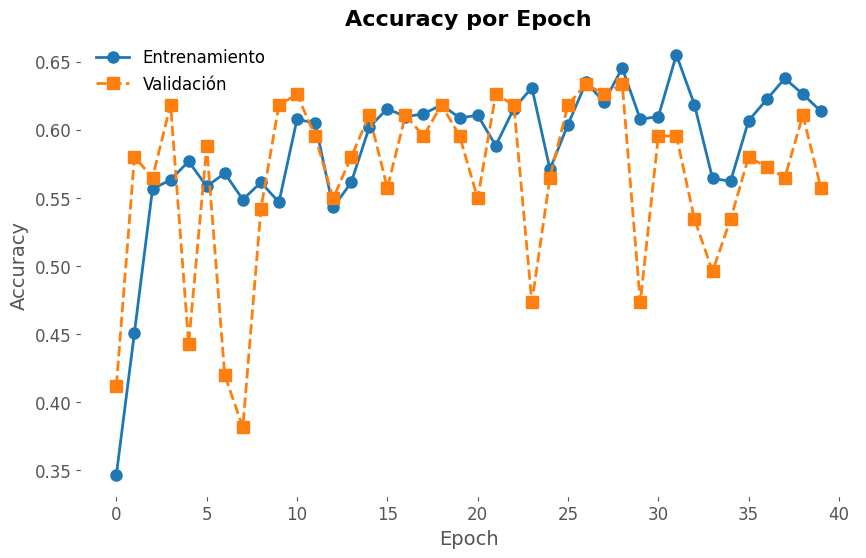

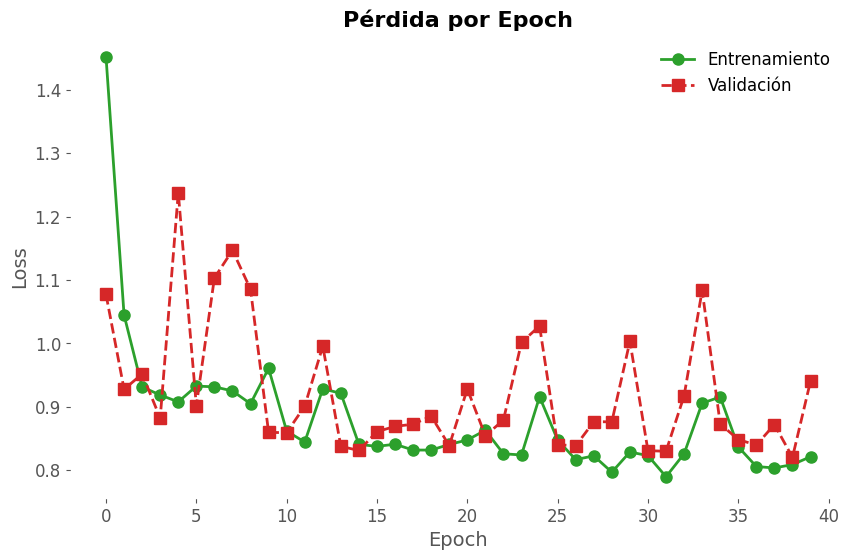

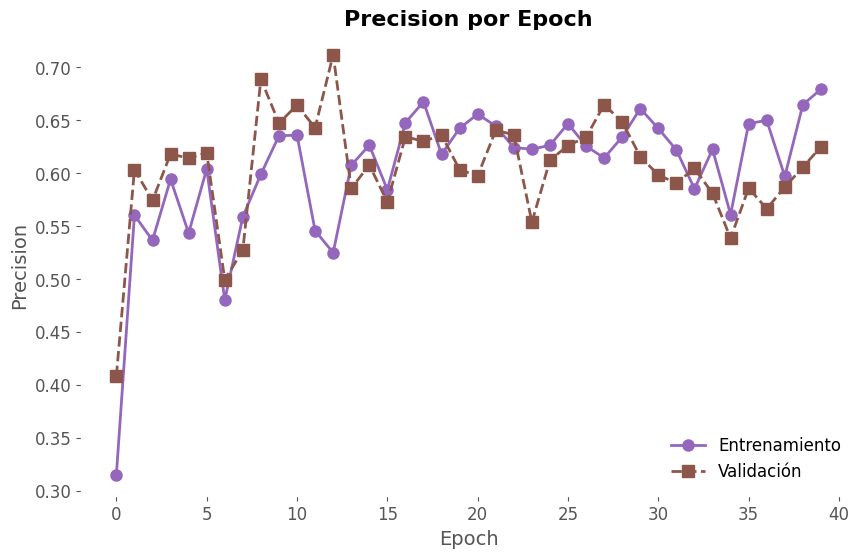

In [ ]:
# Accuracy por epoch
plt.figure(figsize=(10,6))
plt.plot(history1.history['accuracy'], label='Entrenamiento', color=color_train, linewidth=linewidth, marker='o', markersize=markersize)
plt.plot(history1.history['val_accuracy'], label='Validación', color=color_val, linewidth=linewidth, linestyle='--', marker='s', markersize=markersize)
plt.title('Accuracy por Epoch', fontsize=16, weight='bold')
plt.xlabel('Epoch', fontsize=14)
plt.ylabel('Accuracy', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(fontsize=12, loc='best', frameon=False)
plt.grid(False)
plt.gca().set_facecolor('white')
plt.show()

# Pérdida por epoch
plt.figure(figsize=(10,6))
plt.plot(history1.history['loss'], label='Entrenamiento', color='#2ca02c', linewidth=linewidth, marker='o', markersize=markersize)
plt.plot(history1.history['val_loss'], label='Validación', color='#d62728', linewidth=linewidth, linestyle='--', marker='s', markersize=markersize)
plt.title('Pérdida por Epoch', fontsize=16, weight='bold')
plt.xlabel('Epoch', fontsize=14)
plt.ylabel('Loss', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(fontsize=12, loc='best', frameon=False)
plt.grid(False)
plt.gca().set_facecolor('white')
plt.show()

# Precision por epoch
plt.figure(figsize=(10,6))
plt.plot(precision_callbackmlp1.train_precisions, label='Entrenamiento', color='#9467bd', linewidth=linewidth, marker='o', markersize=markersize)
plt.plot(precision_callbackmlp1.val_precisions, label='Validación', color='#8c564b', linewidth=linewidth, linestyle='--', marker='s', markersize=markersize)
plt.title('Precision por Epoch', fontsize=16, weight='bold')
plt.xlabel('Epoch', fontsize=14)
plt.ylabel('Precision', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(fontsize=12, loc='best', frameon=False)
plt.grid(False)
plt.gca().set_facecolor('white')
plt.show()


**Métricas por clase para el del hiperparámetro optimizado**

In [ ]:
precision_accuracy_por_clase(model1, test_ds_pre)


Accuracy global: 0.5891
Precision macro global: 0.6044

--- Métricas por clase ---
Clase healthy: Accuracy = 0.4545 | Precision = 0.6061
Clase angular_leaf_spot: Accuracy = 0.6279 | Precision = 0.4821
Clase bean_rust: Accuracy = 0.6905 | Precision = 0.7250


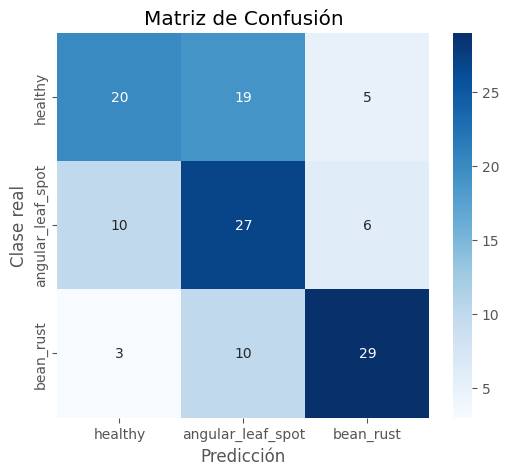

In [ ]:
plot_confusion_matrix(model1, test_ds_pre)

#CNN

In [ ]:
#CNN con LR 0.0001
modelo_cnn1 = keras.models.Sequential()

# Primer bloque
modelo_cnn1.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(128,128,3)))
modelo_cnn1.add(layers.MaxPooling2D((2, 2))) # Reducción de dimensionalidad

# Segundo bloque
modelo_cnn1.add(layers.Conv2D(64, (3, 3), activation='relu'))
modelo_cnn1.add(layers.MaxPooling2D((2, 2)))

# Tercer bloque
modelo_cnn1.add(layers.Conv2D(64, (3, 3), activation='relu'))
modelo_cnn1.add(layers.MaxPooling2D((2, 2)))

# Cuarto bloque
modelo_cnn1.add(layers.Conv2D(32, (3, 3), activation='relu'))
modelo_cnn1.add(layers.MaxPooling2D((2, 2)))

# Quinto bloque
modelo_cnn1.add(layers.Conv2D(64, (3, 3), activation='relu'))
modelo_cnn1.add(layers.MaxPooling2D((2, 2)))

# Aplanar
modelo_cnn1.add(layers.Flatten())
modelo_cnn1.add(layers.Dense(64,activation="relu"))

# Clasificación
modelo_cnn1.add(layers.Dense(3, activation='softmax'))
modelo_cnn1.summary()


modelo_cnn1.compile( optimizer=Adam(learning_rate=0.0001),  loss='sparse_categorical_crossentropy',  metrics=['accuracy'])

precision_callbackcnn1 = PrecisionPerEpoch(train_ds_for_metrics, val_ds_pre)

history_cnn1 = modelo_cnn1.fit(train_ds_aug,validation_data=val_ds_pre,epochs=40,batch_size=64,callbacks=[precision_callbackcnn1])


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 12, 12, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 4, 4, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 2, 2, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,923 (429.39 KB)

 Trainable params: 109,923 (429.39 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 192ms/step - accuracy: 0.3183 - loss: 1.0970Epoch 1 - Precision Train: 0.5726 - Precision Val: 0.4000
17/17 ━━━━━━━━━━━━━━━━━━━━ 17s 456ms/step - accuracy: 0.3211 - loss: 1.0968 - val_accuracy: 0.4733 - val_loss: 1.0836
Epoch 2/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


15/17 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.4955 - loss: 1.0797Epoch 2 - Precision Train: 0.5476 - Precision Val: 0.4910
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 129ms/step - accuracy: 0.4950 - loss: 1.0787 - val_accuracy: 0.5420 - val_loss: 1.0555
Epoch 3/40
15/17 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.5633 - loss: 1.0518Epoch 3 - Precision Train: 0.5891 - Precision Val: 0.6321
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 138ms/step - accuracy: 0.5584 - loss: 1.0507 - val_accuracy: 0.6260 - val_loss: 1.0159
Epoch 4/40
15/17 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.5495 - loss: 1.0067Epoch 4 - Precision Train: 0.4962 - Precision Val: 0.4444
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 132ms/step - accuracy: 0.5489 - loss: 1.0050 - val_accuracy: 0.3740 - val_loss: 1.0869
Epoch 5/40
15/17 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.4987 - loss: 0.9851Epoch 5 - Precision Train: 0.5487 - Precision Val: 0.5987
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 124ms/step - accuracy: 0.5044 - loss: 0.9810 - val_accuracy: 0

In [ ]:
#CNN con LR 0.001
modelo_cnn2 = keras.models.Sequential()

# Primer bloque
modelo_cnn2.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(128,128,3)))
modelo_cnn2.add(layers.MaxPooling2D((2, 2))) # Reducción de dimensionalidad

# Segundo bloque
modelo_cnn2.add(layers.Conv2D(64, (3, 3), activation='relu'))
modelo_cnn2.add(layers.MaxPooling2D((2, 2)))

# Tercer bloque
modelo_cnn2.add(layers.Conv2D(64, (3, 3), activation='relu'))
modelo_cnn2.add(layers.MaxPooling2D((2, 2)))

# Cuarto bloque
modelo_cnn2.add(layers.Conv2D(32, (3, 3), activation='relu'))
modelo_cnn2.add(layers.MaxPooling2D((2, 2)))

# Quinto bloque
modelo_cnn2.add(layers.Conv2D(64, (3, 3), activation='relu'))
modelo_cnn2.add(layers.MaxPooling2D((2, 2)))

# Aplanar
modelo_cnn2.add(layers.Flatten())
modelo_cnn2.add(layers.Dense(64,activation="relu"))

# Clasificación
modelo_cnn2.add(layers.Dense(3, activation='softmax'))

modelo_cnn2.compile( optimizer=Adam(learning_rate=0.001),  loss='sparse_categorical_crossentropy',  metrics=['accuracy'])

precision_callbackcnn2 = PrecisionPerEpoch(train_ds_for_metrics, val_ds_pre)


history_cnn2 = modelo_cnn2.fit(train_ds_aug,validation_data=val_ds_pre,epochs=40,batch_size=64,callbacks=[precision_callbackcnn2])

Epoch 1/40


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step - accuracy: 0.3358 - loss: 1.0881Epoch 1 - Precision Train: 0.3372 - Precision Val: 0.3746
17/17 ━━━━━━━━━━━━━━━━━━━━ 11s 379ms/step - accuracy: 0.3392 - loss: 1.0871 - val_accuracy: 0.4351 - val_loss: 1.1378
Epoch 2/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


15/17 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.5058 - loss: 0.9975Epoch 2 - Precision Train: 0.6035 - Precision Val: 0.6691
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 142ms/step - accuracy: 0.5061 - loss: 0.9952 - val_accuracy: 0.5267 - val_loss: 1.0191
Epoch 3/40
15/17 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.6148 - loss: 0.9089Epoch 3 - Precision Train: 0.5938 - Precision Val: 0.6284
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 126ms/step - accuracy: 0.6113 - loss: 0.9076 - val_accuracy: 0.5725 - val_loss: 0.9167
Epoch 4/40
15/17 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.6371 - loss: 0.8510Epoch 4 - Precision Train: 0.6874 - Precision Val: 0.7107
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 150ms/step - accuracy: 0.6369 - loss: 0.8483 - val_accuracy: 0.6718 - val_loss: 0.7980
Epoch 5/40
15/17 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.6508 - loss: 0.7755Epoch 5 - Precision Train: 0.6326 - Precision Val: 0.6273
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 124ms/step - accuracy: 0.6500 - loss: 0.7792 - val_accuracy: 0

In [ ]:
#CNN con LR 0.0005
modelo_cnn3 = keras.models.Sequential()

# Primer bloque
modelo_cnn3.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(128,128,3)))
modelo_cnn3.add(layers.MaxPooling2D((2, 2))) # Reducción de dimensionalidad

# Segundo bloque
modelo_cnn3.add(layers.Conv2D(64, (3, 3), activation='relu'))
modelo_cnn3.add(layers.MaxPooling2D((2, 2)))

# Tercer bloque
modelo_cnn3.add(layers.Conv2D(64, (3, 3), activation='relu'))
modelo_cnn3.add(layers.MaxPooling2D((2, 2)))

# Cuarto bloque
modelo_cnn3.add(layers.Conv2D(32, (3, 3), activation='relu'))
modelo_cnn3.add(layers.MaxPooling2D((2, 2)))

# Quinto bloque
modelo_cnn3.add(layers.Conv2D(64, (3, 3), activation='relu'))
modelo_cnn3.add(layers.MaxPooling2D((2, 2)))

# Aplanar
modelo_cnn3.add(layers.Flatten())
modelo_cnn3.add(layers.Dense(64,activation="relu"))

# Clasificación
modelo_cnn3.add(layers.Dense(3, activation='softmax'))


modelo_cnn3.compile( optimizer=Adam(learning_rate=0.0005),  loss='sparse_categorical_crossentropy',  metrics=['accuracy'])

precision_callbackcnn3 = PrecisionPerEpoch(train_ds_for_metrics, val_ds_pre)


history_cnn3 = modelo_cnn3.fit(train_ds_aug,validation_data=val_ds_pre,epochs=40,batch_size=64,callbacks=[precision_callbackcnn3])

Epoch 1/40


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step - accuracy: 0.3433 - loss: 1.0976Epoch 1 - Precision Train: 0.5698 - Precision Val: 0.4781
17/17 ━━━━━━━━━━━━━━━━━━━━ 13s 514ms/step - accuracy: 0.3440 - loss: 1.0976 - val_accuracy: 0.4809 - val_loss: 1.0795
Epoch 2/40
15/17 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.5806 - loss: 1.0526Epoch 2 - Precision Train: 0.5857 - Precision Val: 0.6248
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 124ms/step - accuracy: 0.5784 - loss: 1.0469 - val_accuracy: 0.6183 - val_loss: 0.8982
Epoch 3/40
15/17 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.5637 - loss: 0.9428Epoch 3 - Precision Train: 0.6587 - Precision Val: 0.6634
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 129ms/step - accuracy: 0.5621 - loss: 0.9412 - val_accuracy: 0.5954 - val_loss: 0.8982
Epoch 4/40
16/17 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.5948 - loss: 0.9098Epoch 4 - Precision Train: 0.6552 - Precision Val: 0.6497
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 176ms/step - accuracy: 0.5961 - loss: 0.9056 - val_accuracy:

**Valoración del rendimiento en el set de testeo**

Para acuraccy

In [ ]:
score = modelo_cnn1.evaluate(test_ds_pre, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])
score = modelo_cnn2.evaluate(test_ds_pre, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])
score = modelo_cnn3.evaluate(test_ds_pre, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])


Test loss: 0.750866711139679
Test accuracy: 0.6666666865348816
Test loss: 0.6186900734901428
Test accuracy: 0.7364341020584106
Test loss: 0.7285165786743164
Test accuracy: 0.7364341020584106


Para precision

In [ ]:
prec1 = precision_model(modelo_cnn1, test_ds_pre)
print(f"Test Precision: {prec1:.4f}")
prec2 = precision_model(modelo_cnn2, test_ds_pre)
print(f"Test Precision: {prec2:.4f}")
prec3 = precision_model(modelo_cnn3, test_ds_pre)
print(f"Test Precision: {prec3:.4f}")

Test Precision: 0.7425
Test Precision: 0.7755
Test Precision: 0.7743


**Gráficos con el hiperparámetro optimizado**

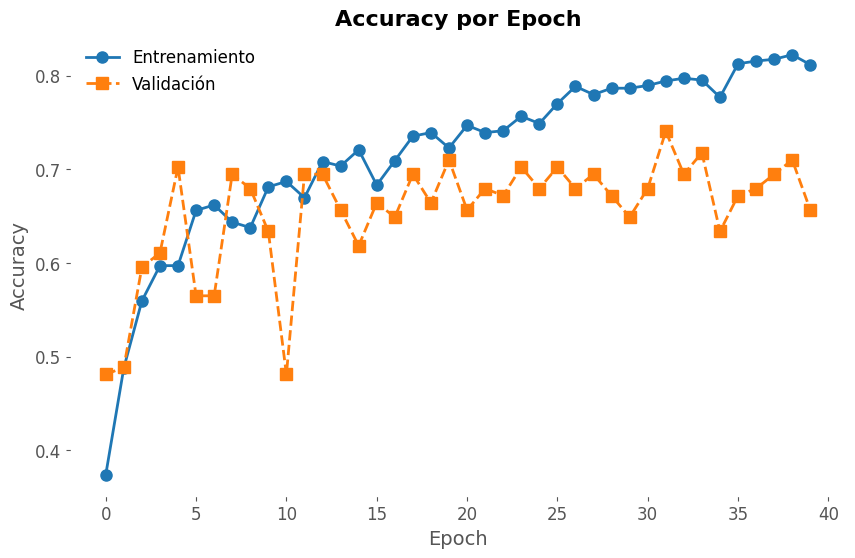

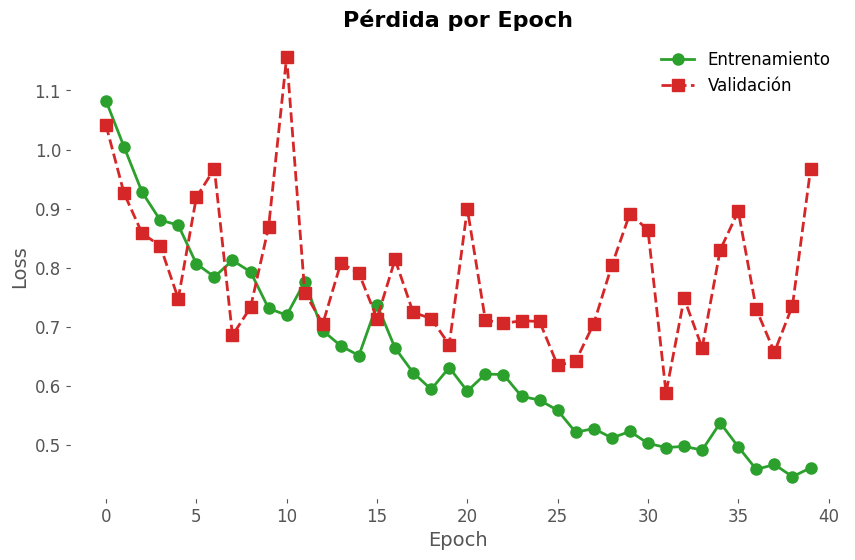

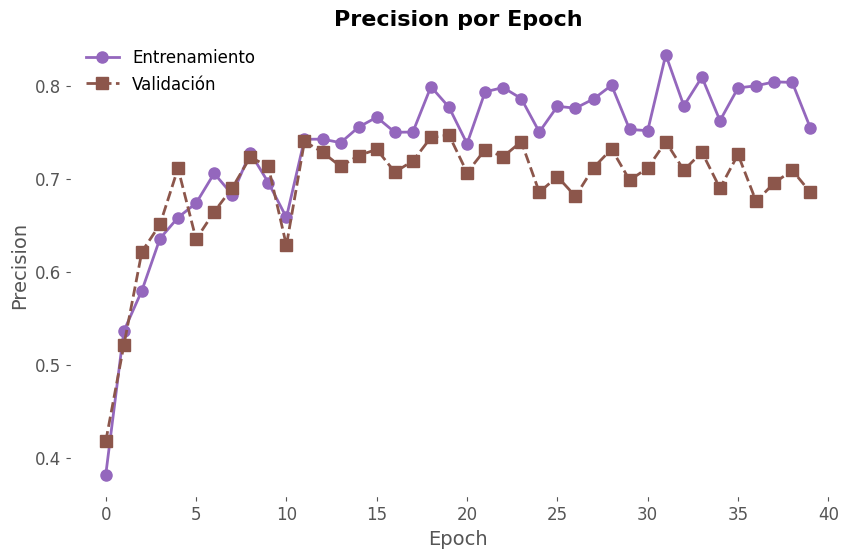

In [ ]:

# Accuracy por epoch
plt.figure(figsize=(10,6))
plt.plot(history_cnn3.history['accuracy'], label='Entrenamiento', color=color_train, linewidth=linewidth, marker='o', markersize=markersize)
plt.plot(history_cnn3.history['val_accuracy'], label='Validación', color=color_val, linewidth=linewidth, linestyle='--', marker='s', markersize=markersize)
plt.title('Accuracy por Epoch', fontsize=16, weight='bold')
plt.xlabel('Epoch', fontsize=14)
plt.ylabel('Accuracy', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(fontsize=12, loc='best', frameon=False)
plt.grid(False)
plt.gca().set_facecolor('white')
plt.show()

# Pérdida por epoch
plt.figure(figsize=(10,6))
plt.plot(history_cnn3.history['loss'], label='Entrenamiento', color='#2ca02c', linewidth=linewidth, marker='o', markersize=markersize)
plt.plot(history_cnn3.history['val_loss'], label='Validación', color='#d62728', linewidth=linewidth, linestyle='--', marker='s', markersize=markersize)
plt.title('Pérdida por Epoch', fontsize=16, weight='bold')
plt.xlabel('Epoch', fontsize=14)
plt.ylabel('Loss', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(fontsize=12, loc='best', frameon=False)
plt.grid(False)
plt.gca().set_facecolor('white')
plt.show()

# Precision por epoch
plt.figure(figsize=(10,6))
plt.plot(precision_callbackcnn3.train_precisions, label='Entrenamiento', color='#9467bd', linewidth=linewidth, marker='o', markersize=markersize)
plt.plot(precision_callbackcnn3.val_precisions, label='Validación', color='#8c564b', linewidth=linewidth, linestyle='--', marker='s', markersize=markersize)
plt.title('Precision por Epoch', fontsize=16, weight='bold')
plt.xlabel('Epoch', fontsize=14)
plt.ylabel('Precision', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(fontsize=12, loc='best', frameon=False)
plt.grid(False)
plt.gca().set_facecolor('white')
plt.show()


**Métricas por clase para el del hiperparámetro optimizado**



In [ ]:
precision_accuracy_por_clase(modelo_cnn3, test_ds_pre)


Accuracy global: 0.7752
Precision macro global: 0.7884

--- Métricas por clase ---
Clase healthy: Accuracy = 0.6818 | Precision = 0.8333
Clase angular_leaf_spot: Accuracy = 0.7907 | Precision = 0.6538
Clase bean_rust: Accuracy = 0.8571 | Precision = 0.8780


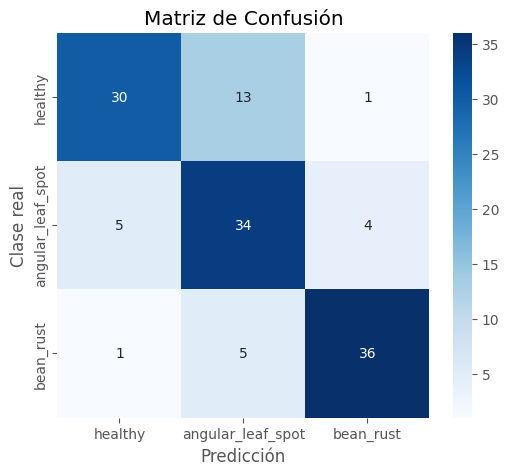

In [ ]:
plot_confusion_matrix(modelo_cnn3, test_ds_pre)

#Modelo con Dropout

In [ ]:
#MLP DP p= 0.4
model_dp1 = models.Sequential()
model_dp1.add(layers.Flatten(input_shape=(128, 128, 3)))

model_dp1.add(layers.Dense(512, activation='relu'))
model_dp1.add(layers.Dropout(0.4))

model_dp1.add(layers.Dense(256, activation='relu'))
model_dp1.add(layers.Dropout(0.4))

model_dp1.add(layers.Dense(128, activation='relu'))
model_dp1.add(layers.Dropout(0.4))

model_dp1.add(layers.Dense(3, activation='softmax'))  # 3 clases


model_dp1.compile( optimizer=optimizers.Adam(learning_rate=0.0001),  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
#model_dp1.summary()

precision_callbackdp1 = PrecisionPerEpoch(train_ds_for_metrics, val_ds_pre)

history_dp1 = model_dp1.fit(train_ds_aug,validation_data=val_ds_pre,epochs=40,batch_size=64,callbacks=[precision_callbackdp1])

Epoch 1/40


/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step - accuracy: 0.2976 - loss: 2.1720

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 1 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 9s 289ms/step - accuracy: 0.2990 - loss: 2.1724 - val_accuracy: 0.3130 - val_loss: 1.1974
Epoch 2/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3770 - loss: 1.6257Epoch 2 - Precision Train: 0.3022 - Precision Val: 0.3504
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 102ms/step - accuracy: 0.3716 - loss: 1.5930 - val_accuracy: 0.4504 - val_loss: 1.0803
Epoch 3/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3250 - loss: 1.1899Epoch 3 - Precision Train: 0.5110 - Precision Val: 0.6663
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 159ms/step - accuracy: 0.3346 - loss: 1.1812 - val_accuracy: 0.5115 - val_loss: 1.0657
Epoch 4/40
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4199 - loss: 1.0734Epoch 4 - Precision Train: 0.5135 - Precision Val: 0.5498
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 113ms/step - accuracy: 0.4182 - loss: 1.0741 - val_accuracy: 0.5115 - val_loss: 1.0628
Epoch 5/40
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3997 - loss: 1.0757Epoch 5 - Precision Train: 0.5388 - Precision Val: 0.5089
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - accuracy: 0.3989 - loss: 1.0759 - val_accuracy: 0.4962 - val_loss: 1.0657
Epoch 6/40
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3795 - loss: 1.0788Epoch 6 - Precision Train: 0.3408 - Precision Val: 0.3510
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 103ms/step - accuracy: 0.3809 - loss: 1.0786 - val_accuracy: 0

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3578 - loss: 1.0892Epoch 7 - Precision Train: 0.5119 - Precision Val: 0.5394
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 120ms/step - accuracy: 0.3593 - loss: 1.0887 - val_accuracy: 0.5496 - val_loss: 1.0589
Epoch 8/40
15/17 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.4239 - loss: 1.0653Epoch 8 - Precision Train: 0.4794 - Precision Val: 0.5622
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 118ms/step - accuracy: 0.4242 - loss: 1.0641 - val_accuracy: 0.5267 - val_loss: 1.0575
Epoch 9/40
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4446 - loss: 1.0465Epoch 9 - Precision Train: 0.5335 - Precision Val: 0.5603
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - accuracy: 0.4443 - loss: 1.0467 - val_accuracy: 0.5496 - val_loss: 1.0380
Epoch 10/40
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4567 - loss: 1.0338Epoch 10 - Precision Train: 0.6284 - Precision Val: 0.6996
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - accuracy: 0.4562 - loss: 1.0340 - val_accuracy:

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3539 - loss: 1.0872

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 12 - Precision Train: 0.2256 - Precision Val: 0.2152
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 113ms/step - accuracy: 0.3610 - loss: 1.0816 - val_accuracy: 0.3893 - val_loss: 1.0308
Epoch 13/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


16/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3421 - loss: 1.0926Epoch 13 - Precision Train: 0.3047 - Precision Val: 0.3551
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 104ms/step - accuracy: 0.3436 - loss: 1.0921 - val_accuracy: 0.4580 - val_loss: 1.0544
Epoch 14/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3463 - loss: 1.0728

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 14 - Precision Train: 0.2633 - Precision Val: 0.2576
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 115ms/step - accuracy: 0.3466 - loss: 1.0726 - val_accuracy: 0.4046 - val_loss: 1.0288
Epoch 15/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3546 - loss: 1.0545

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 15 - Precision Train: 0.2372 - Precision Val: 0.2407
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 123ms/step - accuracy: 0.3616 - loss: 1.0550 - val_accuracy: 0.3969 - val_loss: 1.0174
Epoch 16/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3629 - loss: 1.0722Epoch 16 - Precision Train: 0.2196 - Precision Val: 0.2140
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 106ms/step - accuracy: 0.3671 - loss: 1.0698 - val_accuracy: 0.3893 - val_loss: 1.0115
Epoch 17/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3743 - loss: 1.0708

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 17 - Precision Train: 0.2556 - Precision Val: 0.2626
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 121ms/step - accuracy: 0.3743 - loss: 1.0706 - val_accuracy: 0.4122 - val_loss: 1.0145
Epoch 18/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3806 - loss: 1.0603

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 18 - Precision Train: 0.2446 - Precision Val: 0.2528
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 115ms/step - accuracy: 0.3808 - loss: 1.0601 - val_accuracy: 0.4122 - val_loss: 1.0085
Epoch 19/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3667 - loss: 1.0652

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 19 - Precision Train: 0.1789 - Precision Val: 0.1572
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - accuracy: 0.3741 - loss: 1.0622 - val_accuracy: 0.3664 - val_loss: 1.0129
Epoch 20/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4095 - loss: 1.0636Epoch 20 - Precision Train: 0.5043 - Precision Val: 0.5441
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 116ms/step - accuracy: 0.4113 - loss: 1.0620 - val_accuracy: 0.5191 - val_loss: 1.0009
Epoch 21/40
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4189 - loss: 1.0517Epoch 21 - Precision Train: 0.5336 - Precision Val: 0.5150
17/17 ━━━━━━━━━━━━━━━━━━━━ 6s 159ms/step - accuracy: 0.4190 - loss: 1.0515 - val_accuracy: 0.5420 - val_loss: 1.0035
Epoch 22/40
13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.4356 - loss: 1.0460Epoch 22 - Precision Train: 0.5483 - Precision Val: 0.5319
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 103ms/step - accuracy: 0.4370 - loss: 1.0471 - val_accuracy: 0.5496 - val_loss: 1.0168
Epoch 23/40
13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.4639 - loss: 1.0260Epoch 23 - Precision Train: 0.5466 - Precision Val: 0.5371
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 106ms/step - accuracy: 0.4603 - loss: 1.0282 - val_accu

In [ ]:
#MLP DP p= 0.5

model_dp2 = models.Sequential()
model_dp2.add(layers.Flatten(input_shape=(128, 128, 3)))

model_dp2.add(layers.Dense(512, activation='relu'))
model_dp2.add(layers.Dropout(0.5))

model_dp2.add(layers.Dense(256, activation='relu'))
model_dp2.add(layers.Dropout(0.5))

model_dp2.add(layers.Dense(128, activation='relu'))
model_dp2.add(layers.Dropout(0.5))

model_dp2.add(layers.Dense(3, activation='softmax'))  # 3 clases

model_dp2.compile( optimizer=optimizers.Adam(learning_rate=0.0001),  loss='sparse_categorical_crossentropy', metrics=['accuracy'])

precision_callbackdp2 = PrecisionPerEpoch(train_ds_for_metrics, val_ds_pre)

history_dp2 = model_dp2.fit(train_ds_aug,validation_data=val_ds_pre,epochs=40,batch_size=64,callbacks=[precision_callbackdp2])

Epoch 1/40


/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step - accuracy: 0.3444 - loss: 2.7300

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 1 - Precision Train: 0.1132 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 9s 301ms/step - accuracy: 0.3447 - loss: 2.7309 - val_accuracy: 0.3130 - val_loss: 1.1208
Epoch 2/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3284 - loss: 1.9535Epoch 2 - Precision Train: 0.4341 - Precision Val: 0.2300
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 127ms/step - accuracy: 0.3286 - loss: 1.9363 - val_accuracy: 0.3435 - val_loss: 1.0974
Epoch 3/40
13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3488 - loss: 1.1160Epoch 3 - Precision Train: 0.4126 - Precision Val: 0.3077
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - accuracy: 0.3437 - loss: 1.1161 - val_accuracy: 0.4656 - val_loss: 1.0947
Epoch 4/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3180 - loss: 1.0938Epoch 4 - Precision Train: 0.3020 - Precision Val: 0.2665
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 106ms/step - accuracy: 0.3159 - loss: 1.0948 - val_accuracy: 0.3893 - val_loss: 1.0890
Epoch 5/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3209 - loss: 1.1017

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 5 - Precision Train: 0.1803 - Precision Val: 0.4385
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 111ms/step - accuracy: 0.3212 - loss: 1.1016 - val_accuracy: 0.3206 - val_loss: 1.0967
Epoch 6/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.2908 - loss: 1.0986Epoch 6 - Precision Train: 0.3614 - Precision Val: 0.4341
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 105ms/step - accuracy: 0.2975 - loss: 1.0986 - val_accuracy: 0.3053 - val_loss: 1.0986
Epoch 7/40
16/17 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.3291 - loss: 1.0997

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 7 - Precision Train: 0.1946 - Precision Val: 0.1000
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 129ms/step - accuracy: 0.3289 - loss: 1.0998 - val_accuracy: 0.2977 - val_loss: 1.0987
Epoch 8/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3462 - loss: 1.1003

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 8 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 110ms/step - accuracy: 0.3457 - loss: 1.1003 - val_accuracy: 0.3130 - val_loss: 1.0987
Epoch 9/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3421 - loss: 1.0985

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 9 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 106ms/step - accuracy: 0.3417 - loss: 1.0986 - val_accuracy: 0.3130 - val_loss: 1.0988
Epoch 10/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


16/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3250 - loss: 1.1031Epoch 10 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 103ms/step - accuracy: 0.3261 - loss: 1.1028 - val_accuracy: 0.3130 - val_loss: 1.0988
Epoch 11/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3369 - loss: 1.0986

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 11 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 153ms/step - accuracy: 0.3391 - loss: 1.0990 - val_accuracy: 0.3130 - val_loss: 1.0988
Epoch 12/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3351 - loss: 1.0986

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 12 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 112ms/step - accuracy: 0.3352 - loss: 1.0986 - val_accuracy: 0.3130 - val_loss: 1.0988
Epoch 13/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3397 - loss: 1.0986

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 13 - Precision Train: 0.1114 - Precision Val: 0.1000
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 115ms/step - accuracy: 0.3366 - loss: 1.0986 - val_accuracy: 0.2977 - val_loss: 1.0988
Epoch 14/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3325 - loss: 1.0987Epoch 14 - Precision Train: 0.1114 - Precision Val: 0.1000
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 109ms/step - accuracy: 0.3336 - loss: 1.0987 - val_accuracy: 0.2977 - val_loss: 1.0988
Epoch 15/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3346 - loss: 1.0985

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 15 - Precision Train: 0.1114 - Precision Val: 0.1000
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 109ms/step - accuracy: 0.3278 - loss: 1.0985 - val_accuracy: 0.2977 - val_loss: 1.0989
Epoch 16/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3552 - loss: 1.0985Epoch 16 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - accuracy: 0.3517 - loss: 1.0985 - val_accuracy: 0.3130 - val_loss: 1.0989
Epoch 17/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3674 - loss: 1.0985Epoch 17 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - accuracy: 0.3640 - loss: 1.0985 - val_accuracy: 0.3130 - val_loss: 1.0989
Epoch 18/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


14/17 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.3525 - loss: 1.0985

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 18 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 133ms/step - accuracy: 0.3483 - loss: 1.0985 - val_accuracy: 0.3130 - val_loss: 1.0989
Epoch 19/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


16/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3366 - loss: 1.0987

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 19 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - accuracy: 0.3363 - loss: 1.0987 - val_accuracy: 0.3130 - val_loss: 1.0989
Epoch 20/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.3596 - loss: 1.0991Epoch 20 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - accuracy: 0.3526 - loss: 1.0995 - val_accuracy: 0.3130 - val_loss: 1.0989
Epoch 21/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3145 - loss: 1.0986

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 21 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 114ms/step - accuracy: 0.3177 - loss: 1.0986 - val_accuracy: 0.3130 - val_loss: 1.0989
Epoch 22/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3447 - loss: 1.0985

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 22 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 116ms/step - accuracy: 0.3445 - loss: 1.0985 - val_accuracy: 0.3130 - val_loss: 1.0989
Epoch 23/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


16/17 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.3647 - loss: 1.0985

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 23 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 115ms/step - accuracy: 0.3630 - loss: 1.0985 - val_accuracy: 0.3130 - val_loss: 1.0990
Epoch 24/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3287 - loss: 1.0985Epoch 24 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 103ms/step - accuracy: 0.3319 - loss: 1.0985 - val_accuracy: 0.3130 - val_loss: 1.0990
Epoch 25/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3604 - loss: 1.0985

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 25 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 112ms/step - accuracy: 0.3592 - loss: 1.0985 - val_accuracy: 0.3130 - val_loss: 1.0990
Epoch 26/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


16/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3453 - loss: 1.0984Epoch 26 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 102ms/step - accuracy: 0.3445 - loss: 1.0985 - val_accuracy: 0.3130 - val_loss: 1.0990
Epoch 27/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


16/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3348 - loss: 1.0987Epoch 27 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 156ms/step - accuracy: 0.3354 - loss: 1.0987 - val_accuracy: 0.3130 - val_loss: 1.0990
Epoch 28/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3396 - loss: 1.0986Epoch 28 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 110ms/step - accuracy: 0.3398 - loss: 1.0986 - val_accuracy: 0.3130 - val_loss: 1.0991
Epoch 29/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3369 - loss: 1.0987Epoch 29 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 103ms/step - accuracy: 0.3377 - loss: 1.0986 - val_accuracy: 0.3130 - val_loss: 1.0991
Epoch 30/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3485 - loss: 1.0984Epoch 30 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 122ms/step - accuracy: 0.3480 - loss: 1.0984 - val_accuracy: 0.3130 - val_loss: 1.0991
Epoch 31/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3493 - loss: 1.0984

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 31 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 111ms/step - accuracy: 0.3487 - loss: 1.0984 - val_accuracy: 0.3130 - val_loss: 1.0992
Epoch 32/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3410 - loss: 1.0985Epoch 32 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 103ms/step - accuracy: 0.3409 - loss: 1.0985 - val_accuracy: 0.3130 - val_loss: 1.0992
Epoch 33/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3480 - loss: 1.0983Epoch 33 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 106ms/step - accuracy: 0.3477 - loss: 1.0984 - val_accuracy: 0.3130 - val_loss: 1.0993
Epoch 34/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3431 - loss: 1.0985

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 34 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 117ms/step - accuracy: 0.3429 - loss: 1.0985 - val_accuracy: 0.3130 - val_loss: 1.0993
Epoch 35/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


14/17 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.3329 - loss: 1.0988Epoch 35 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 155ms/step - accuracy: 0.3347 - loss: 1.0987 - val_accuracy: 0.3130 - val_loss: 1.0994
Epoch 36/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3417 - loss: 1.0986Epoch 36 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 104ms/step - accuracy: 0.3417 - loss: 1.0986 - val_accuracy: 0.3130 - val_loss: 1.0994
Epoch 37/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3681 - loss: 1.0983Epoch 37 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 106ms/step - accuracy: 0.3611 - loss: 1.0983 - val_accuracy: 0.3130 - val_loss: 1.0994
Epoch 38/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3368 - loss: 1.0984

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 38 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 110ms/step - accuracy: 0.3373 - loss: 1.0984 - val_accuracy: 0.3130 - val_loss: 1.0995
Epoch 39/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3463 - loss: 1.0985

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 39 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 129ms/step - accuracy: 0.3450 - loss: 1.0985 - val_accuracy: 0.3130 - val_loss: 1.0995
Epoch 40/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3358 - loss: 1.0987

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 40 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 110ms/step - accuracy: 0.3359 - loss: 1.0987 - val_accuracy: 0.3130 - val_loss: 1.0996


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
#MLP DP p= 0.6

model_dp3 = models.Sequential()
model_dp3.add(layers.Flatten(input_shape=(128, 128, 3)))

model_dp3.add(layers.Dense(512, activation='relu'))
model_dp3.add(layers.Dropout(0.6))

model_dp3.add(layers.Dense(256, activation='relu'))
model_dp3.add(layers.Dropout(0.6))

model_dp3.add(layers.Dense(128, activation='relu'))
model_dp3.add(layers.Dropout(0.6))

model_dp3.add(layers.Dense(3, activation='softmax'))  # 3 clases

model_dp3.compile( optimizer=optimizers.Adam(learning_rate=0.0001),  loss='sparse_categorical_crossentropy', metrics=['accuracy'])

precision_callbackdp3 = PrecisionPerEpoch(train_ds_for_metrics, val_ds_pre)

history_dp3 = model_dp3.fit(train_ds_aug,validation_data=val_ds_pre,epochs=40,batch_size=64,callbacks=[precision_callbackdp3])

Epoch 1/40


/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step - accuracy: 0.3415 - loss: 3.6118

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 1 - Precision Train: 0.2760 - Precision Val: 0.2959
17/17 ━━━━━━━━━━━━━━━━━━━━ 9s 319ms/step - accuracy: 0.3404 - loss: 3.6240 - val_accuracy: 0.3893 - val_loss: 1.1103
Epoch 2/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.2887 - loss: 1.8238Epoch 2 - Precision Train: 0.5665 - Precision Val: 0.1282
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 106ms/step - accuracy: 0.2897 - loss: 1.8034 - val_accuracy: 0.3817 - val_loss: 1.0983
Epoch 3/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3281 - loss: 1.0985Epoch 3 - Precision Train: 0.2982 - Precision Val: 0.2060
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 109ms/step - accuracy: 0.3294 - loss: 1.0990 - val_accuracy: 0.2824 - val_loss: 1.1025
Epoch 4/40
13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3302 - loss: 1.0976

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 4 - Precision Train: 0.2753 - Precision Val: 0.1282
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 111ms/step - accuracy: 0.3283 - loss: 1.0978 - val_accuracy: 0.3817 - val_loss: 1.0982
Epoch 5/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.3229 - loss: 1.0999Epoch 5 - Precision Train: 0.6505 - Precision Val: 0.1282
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 122ms/step - accuracy: 0.3234 - loss: 1.1000 - val_accuracy: 0.3817 - val_loss: 1.0982
Epoch 6/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3332 - loss: 1.0991Epoch 6 - Precision Train: 0.2753 - Precision Val: 0.1298
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 109ms/step - accuracy: 0.3332 - loss: 1.0992 - val_accuracy: 0.3893 - val_loss: 1.0982
Epoch 7/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3445 - loss: 1.1013Epoch 7 - Precision Train: 0.2915 - Precision Val: 0.3070
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 109ms/step - accuracy: 0.3443 - loss: 1.1014 - val_accuracy: 0.3130 - val_loss: 1.0990
Epoch 8/40
13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3706 - loss: 1.1098Epoch 8 - Precision Train: 0.2795 - Precision Val: 0.1034
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 110ms/step - accuracy: 0.3655 - loss: 1.1081 - val_accuracy: 0.3053 - val_loss: 1.0984
Epoch 9/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


14/17 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.3427 - loss: 1.0986

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 9 - Precision Train: 0.2799 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 133ms/step - accuracy: 0.3402 - loss: 1.0988 - val_accuracy: 0.3130 - val_loss: 1.0984
Epoch 10/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3322 - loss: 1.0987Epoch 10 - Precision Train: 0.1132 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 106ms/step - accuracy: 0.3343 - loss: 1.0987 - val_accuracy: 0.3130 - val_loss: 1.0984
Epoch 11/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3103 - loss: 1.0988

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 11 - Precision Train: 0.2799 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 113ms/step - accuracy: 0.3165 - loss: 1.0988 - val_accuracy: 0.3130 - val_loss: 1.0984
Epoch 12/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3442 - loss: 1.0986Epoch 12 - Precision Train: 0.1132 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 106ms/step - accuracy: 0.3428 - loss: 1.0986 - val_accuracy: 0.3130 - val_loss: 1.0984
Epoch 13/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


16/17 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.3575 - loss: 1.0985

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 13 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 126ms/step - accuracy: 0.3563 - loss: 1.0985 - val_accuracy: 0.3130 - val_loss: 1.0984
Epoch 14/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3326 - loss: 1.0985Epoch 14 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 110ms/step - accuracy: 0.3349 - loss: 1.0986 - val_accuracy: 0.3130 - val_loss: 1.0984
Epoch 15/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3435 - loss: 1.0984Epoch 15 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - accuracy: 0.3433 - loss: 1.0984 - val_accuracy: 0.3130 - val_loss: 1.0985
Epoch 16/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3547 - loss: 1.0994

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 16 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 116ms/step - accuracy: 0.3531 - loss: 1.0999 - val_accuracy: 0.3130 - val_loss: 1.0985
Epoch 17/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.3416 - loss: 1.0985Epoch 17 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 103ms/step - accuracy: 0.3404 - loss: 1.0985 - val_accuracy: 0.3130 - val_loss: 1.0986
Epoch 18/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3354 - loss: 1.0988Epoch 18 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 104ms/step - accuracy: 0.3364 - loss: 1.0987 - val_accuracy: 0.3130 - val_loss: 1.0986
Epoch 19/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3462 - loss: 1.0985

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 19 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - accuracy: 0.3458 - loss: 1.0985 - val_accuracy: 0.3130 - val_loss: 1.0987
Epoch 20/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3927 - loss: 1.0980Epoch 20 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 110ms/step - accuracy: 0.3778 - loss: 1.0982 - val_accuracy: 0.3130 - val_loss: 1.0986
Epoch 21/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3381 - loss: 1.0986

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 21 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - accuracy: 0.3383 - loss: 1.0986 - val_accuracy: 0.3130 - val_loss: 1.0986
Epoch 22/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


16/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3154 - loss: 1.0989Epoch 22 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 105ms/step - accuracy: 0.3182 - loss: 1.0988 - val_accuracy: 0.3130 - val_loss: 1.0987
Epoch 23/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3069 - loss: 1.1030Epoch 23 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 103ms/step - accuracy: 0.3149 - loss: 1.1034 - val_accuracy: 0.3130 - val_loss: 1.0987
Epoch 24/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3323 - loss: 1.0987

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 24 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 111ms/step - accuracy: 0.3340 - loss: 1.0987 - val_accuracy: 0.3130 - val_loss: 1.0987
Epoch 25/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


16/17 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.3378 - loss: 1.0986Epoch 25 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 114ms/step - accuracy: 0.3380 - loss: 1.0986 - val_accuracy: 0.3130 - val_loss: 1.0988
Epoch 26/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3538 - loss: 1.0983Epoch 26 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 106ms/step - accuracy: 0.3530 - loss: 1.0983 - val_accuracy: 0.3130 - val_loss: 1.0988
Epoch 27/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3281 - loss: 1.0989Epoch 27 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 110ms/step - accuracy: 0.3309 - loss: 1.0988 - val_accuracy: 0.3130 - val_loss: 1.0989
Epoch 28/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3209 - loss: 1.0989

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 28 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 122ms/step - accuracy: 0.3262 - loss: 1.0988 - val_accuracy: 0.3130 - val_loss: 1.0989
Epoch 29/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3107 - loss: 1.0991

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 29 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 109ms/step - accuracy: 0.3187 - loss: 1.0989 - val_accuracy: 0.3130 - val_loss: 1.0989
Epoch 30/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3307 - loss: 1.0987Epoch 30 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 106ms/step - accuracy: 0.3338 - loss: 1.0987 - val_accuracy: 0.3130 - val_loss: 1.0990
Epoch 31/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3545 - loss: 1.0984

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 31 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 106ms/step - accuracy: 0.3510 - loss: 1.0985 - val_accuracy: 0.3130 - val_loss: 1.0990
Epoch 32/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3527 - loss: 1.0982Epoch 32 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - accuracy: 0.3488 - loss: 1.0983 - val_accuracy: 0.3130 - val_loss: 1.0990


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 33/40
16/17 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.3336 - loss: 1.0987

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 33 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 129ms/step - accuracy: 0.3344 - loss: 1.0987 - val_accuracy: 0.3130 - val_loss: 1.0990
Epoch 34/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3358 - loss: 1.0985Epoch 34 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - accuracy: 0.3361 - loss: 1.0985 - val_accuracy: 0.3130 - val_loss: 1.0991
Epoch 35/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3429 - loss: 1.0985

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 35 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 114ms/step - accuracy: 0.3428 - loss: 1.0985 - val_accuracy: 0.3130 - val_loss: 1.0991
Epoch 36/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3510 - loss: 1.0985

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 36 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 114ms/step - accuracy: 0.3486 - loss: 1.0985 - val_accuracy: 0.3130 - val_loss: 1.0992
Epoch 37/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


14/17 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.3435 - loss: 1.0985Epoch 37 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 114ms/step - accuracy: 0.3427 - loss: 1.0985 - val_accuracy: 0.3130 - val_loss: 1.0992
Epoch 38/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3197 - loss: 1.0989

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 38 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 112ms/step - accuracy: 0.3253 - loss: 1.0988 - val_accuracy: 0.3130 - val_loss: 1.0993
Epoch 39/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3499 - loss: 1.0983

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 39 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 109ms/step - accuracy: 0.3494 - loss: 1.0983 - val_accuracy: 0.3130 - val_loss: 1.0993
Epoch 40/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3485 - loss: 1.0986Epoch 40 - Precision Train: 0.1134 - Precision Val: 0.1043
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 104ms/step - accuracy: 0.3481 - loss: 1.0986 - val_accuracy: 0.3130 - val_loss: 1.0994


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


**Valoración del rendimiento en el set de testeo**

Para accuracy

In [ ]:
score = model_dp1.evaluate(test_ds_pre, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])
score = model_dp2.evaluate(test_ds_pre, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])
score = model_dp3.evaluate(test_ds_pre, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])

Test loss: 1.0155105590820312
Test accuracy: 0.4651162922382355
Test loss: 1.0987575054168701
Test accuracy: 0.3333333432674408
Test loss: 1.0987170934677124
Test accuracy: 0.3333333432674408


Para precision

In [ ]:
prec1 = precision_model(model_dp1, test_ds_pre)
print(f"Test Precision: {prec1:.4f}")
prec2 = precision_model(model_dp2, test_ds_pre)
print(f"Test Precision: {prec2:.4f}")
prec3 = precision_model(model_dp3, test_ds_pre)
print(f"Test Precision: {prec3:.4f}")

Test Precision: 0.4265


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Test Precision: 0.1111
Test Precision: 0.1111


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


**Gráficos con el hiperparámetro optimizado**

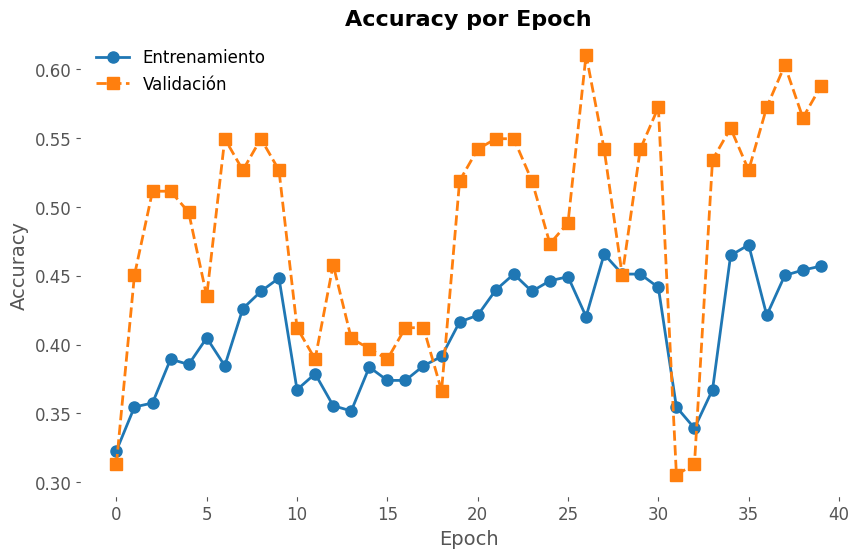

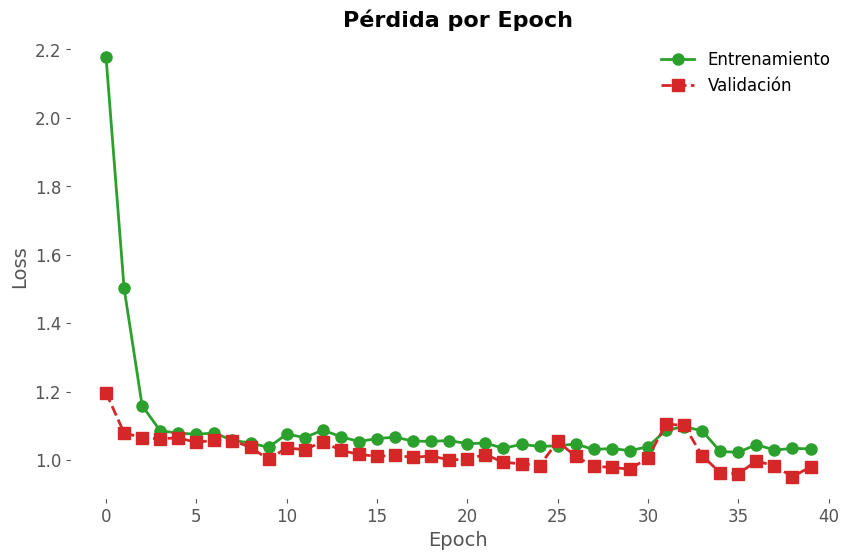

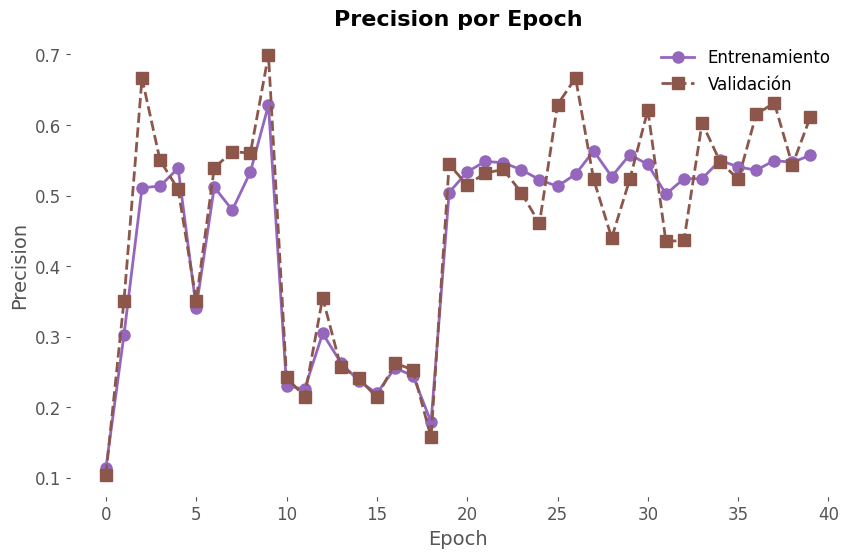

In [ ]:

# Accuracy por epoch
plt.figure(figsize=(10,6))
plt.plot(history_dp1.history['accuracy'], label='Entrenamiento', color=color_train, linewidth=linewidth, marker='o', markersize=markersize)
plt.plot(history_dp1.history['val_accuracy'], label='Validación', color=color_val, linewidth=linewidth, linestyle='--', marker='s', markersize=markersize)
plt.title('Accuracy por Epoch', fontsize=16, weight='bold')
plt.xlabel('Epoch', fontsize=14)
plt.ylabel('Accuracy', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(fontsize=12, loc='best', frameon=False)
plt.grid(False)
plt.gca().set_facecolor('white')
plt.show()

# Pérdida por epoch
plt.figure(figsize=(10,6))
plt.plot(history_dp1.history['loss'], label='Entrenamiento', color='#2ca02c', linewidth=linewidth, marker='o', markersize=markersize)
plt.plot(history_dp1.history['val_loss'], label='Validación', color='#d62728', linewidth=linewidth, linestyle='--', marker='s', markersize=markersize)
plt.title('Pérdida por Epoch', fontsize=16, weight='bold')
plt.xlabel('Epoch', fontsize=14)
plt.ylabel('Loss', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(fontsize=12, loc='best', frameon=False)
plt.grid(False)
plt.gca().set_facecolor('white')
plt.show()

# Precision por epoch
plt.figure(figsize=(10,6))
plt.plot(precision_callbackdp1.train_precisions, label='Entrenamiento', color='#9467bd', linewidth=linewidth, marker='o', markersize=markersize)
plt.plot(precision_callbackdp1.val_precisions, label='Validación', color='#8c564b', linewidth=linewidth, linestyle='--', marker='s', markersize=markersize)
plt.title('Precision por Epoch', fontsize=16, weight='bold')
plt.xlabel('Epoch', fontsize=14)
plt.ylabel('Precision', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(fontsize=12, loc='best', frameon=False)
plt.grid(False)
plt.gca().set_facecolor('white')
plt.show()


**Métricas por clase para el del hiperparámetro optimizado**

In [ ]:
precision_accuracy_por_clase(model_dp1, test_ds_pre)


Accuracy global: 0.4651
Precision macro global: 0.4265

--- Métricas por clase ---
Clase healthy: Accuracy = 0.4318 | Precision = 0.5758
Clase angular_leaf_spot: Accuracy = 0.0930 | Precision = 0.2353
Clase bean_rust: Accuracy = 0.8810 | Precision = 0.4684


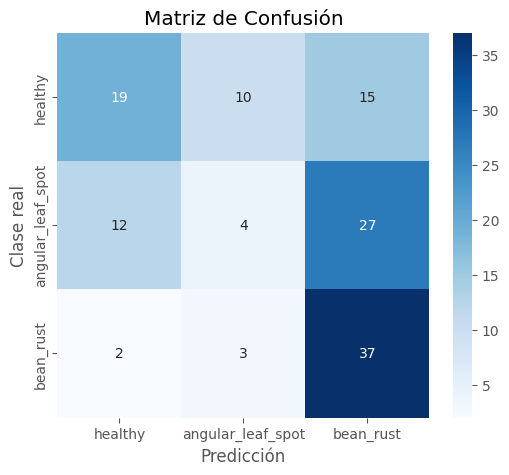

In [ ]:
plot_confusion_matrix(model_dp1, test_ds_pre)

**CNN con dropout**

In [ ]:
# CNN dp con LR 0.0001 0.001 0.0005 y dropout en capa de salida p=0.5
modelo_cnn1dp = keras.models.Sequential()

# Primer bloque
modelo_cnn1dp.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(128,128,3)))
modelo_cnn1dp.add(layers.MaxPooling2D((2, 2)))

# Segundo bloque
modelo_cnn1dp.add(layers.Conv2D(64, (3, 3), activation='relu'))
modelo_cnn1dp.add(layers.MaxPooling2D((2, 2)))

# Tercer bloque
modelo_cnn1dp.add(layers.Conv2D(64, (3, 3), activation='relu'))
modelo_cnn1dp.add(layers.MaxPooling2D((2, 2)))

# Cuarto bloque
modelo_cnn1dp.add(layers.Conv2D(32, (3, 3), activation='relu'))
modelo_cnn1dp.add(layers.MaxPooling2D((2, 2)))

# Quinto bloque
modelo_cnn1dp.add(layers.Conv2D(64, (3, 3), activation='relu'))
modelo_cnn1dp.add(layers.MaxPooling2D((2, 2)))

# Aplanar
modelo_cnn1dp.add(layers.Flatten())
modelo_cnn1dp.add(layers.Dense(64, activation="relu"))

# Dropout
modelo_cnn1dp.add(layers.Dropout(0.5))

# Clasificación
modelo_cnn1dp.add(layers.Dense(3, activation='softmax'))
#modelo_cnn1dp.summary()

# Modelo
modelo_cnn1dp.compile( optimizer=Adam(learning_rate=0.0001), loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

precision_callbackcnn1dp = PrecisionPerEpoch(train_ds_for_metrics, val_ds_pre)

# Entrenamiento
history_cnn1dp = modelo_cnn1dp.fit(train_ds_aug, validation_data=val_ds_pre, epochs=40,batch_size=64,callbacks=[precision_callbackcnn1dp])

Epoch 1/40


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step - accuracy: 0.3707 - loss: 1.0963Epoch 1 - Precision Train: 0.5683 - Precision Val: 0.4390
17/17 ━━━━━━━━━━━━━━━━━━━━ 12s 383ms/step - accuracy: 0.3707 - loss: 1.0962 - val_accuracy: 0.3511 - val_loss: 1.0913
Epoch 2/40
15/17 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.4180 - loss: 1.0860Epoch 2 - Precision Train: 0.5561 - Precision Val: 0.6054
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 175ms/step - accuracy: 0.4197 - loss: 1.0857 - val_accuracy: 0.4809 - val_loss: 1.0761
Epoch 3/40
15/17 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.4810 - loss: 1.0717Epoch 3 - Precision Train: 0.5444 - Precision Val: 0.5671
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 126ms/step - accuracy: 0.4831 - loss: 1.0704 - val_accuracy: 0.5038 - val_loss: 1.0474
Epoch 4/40
15/17 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.4918 - loss: 1.0462Epoch 4 - Precision Train: 0.5915 - Precision Val: 0.6962
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 131ms/step - accuracy: 0.4945 - loss: 1.0437 - val_accuracy:

In [ ]:
# CNN dp con LR 0.001 y dropout en capa de salida p=0.5
modelo_cnn2dp = keras.models.Sequential()

# Primer bloque
modelo_cnn2dp.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(128,128,3)))
modelo_cnn2dp.add(layers.MaxPooling2D((2, 2)))

# Segundo bloque
modelo_cnn2dp.add(layers.Conv2D(64, (3, 3), activation='relu'))
modelo_cnn2dp.add(layers.MaxPooling2D((2, 2)))

# Tercer bloque
modelo_cnn2dp.add(layers.Conv2D(64, (3, 3), activation='relu'))
modelo_cnn2dp.add(layers.MaxPooling2D((2, 2)))

# Cuarto bloque
modelo_cnn2dp.add(layers.Conv2D(32, (3, 3), activation='relu'))
modelo_cnn2dp.add(layers.MaxPooling2D((2, 2)))

# Quinto bloque
modelo_cnn2dp.add(layers.Conv2D(64, (3, 3), activation='relu'))
modelo_cnn2dp.add(layers.MaxPooling2D((2, 2)))

# Aplanar
modelo_cnn2dp.add(layers.Flatten())
modelo_cnn2dp.add(layers.Dense(64, activation="relu"))

# Dropout
modelo_cnn2dp.add(layers.Dropout(0.5))

# Clasificación
modelo_cnn2dp.add(layers.Dense(3, activation='softmax'))

# Modelo
modelo_cnn2dp.compile( optimizer=Adam(learning_rate=0.001), loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

precision_callbackcnn2dp = PrecisionPerEpoch(train_ds_for_metrics, val_ds_pre)

# Entrenamiento
history_cnn2dp = modelo_cnn2dp.fit(train_ds_aug, validation_data=val_ds_pre, epochs=40,batch_size=64,callbacks=[precision_callbackcnn2dp])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/40
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 220ms/step - accuracy: 0.3249 - loss: 1.1012

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 1 - Precision Train: 0.3370 - Precision Val: 0.3231
17/17 ━━━━━━━━━━━━━━━━━━━━ 27s 598ms/step - accuracy: 0.3262 - loss: 1.1010 - val_accuracy: 0.4885 - val_loss: 1.0877
Epoch 2/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


15/17 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.4029 - loss: 1.0838Epoch 2 - Precision Train: 0.3431 - Precision Val: 0.3695
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 138ms/step - accuracy: 0.4035 - loss: 1.0813 - val_accuracy: 0.5420 - val_loss: 0.9765
Epoch 3/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


15/17 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.5004 - loss: 0.9964Epoch 3 - Precision Train: 0.5508 - Precision Val: 0.5767
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 156ms/step - accuracy: 0.4986 - loss: 0.9966 - val_accuracy: 0.5802 - val_loss: 0.9080
Epoch 4/40
15/17 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.5572 - loss: 0.9503Epoch 4 - Precision Train: 0.6083 - Precision Val: 0.6798
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 134ms/step - accuracy: 0.5553 - loss: 0.9500 - val_accuracy: 0.6412 - val_loss: 0.8633
Epoch 5/40
15/17 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.5868 - loss: 0.9043Epoch 5 - Precision Train: 0.6715 - Precision Val: 0.7155
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 128ms/step - accuracy: 0.5874 - loss: 0.9026 - val_accuracy: 0.6947 - val_loss: 0.7640
Epoch 6/40
15/17 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.5760 - loss: 0.9225Epoch 6 - Precision Train: 0.5562 - Precision Val: 0.6024
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 136ms/step - accuracy: 0.5829 - loss: 0.9144 - val_accuracy: 0

In [ ]:
# CNN dp con LR 0.0005 y dropout en capa de salida p=0.5
modelo_cnn3dp = keras.models.Sequential()

# Primer bloque
modelo_cnn3dp.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(128,128,3)))
modelo_cnn3dp.add(layers.MaxPooling2D((2, 2)))

# Segundo bloque
modelo_cnn3dp.add(layers.Conv2D(64, (3, 3), activation='relu'))
modelo_cnn3dp.add(layers.MaxPooling2D((2, 2)))

# Tercer bloque
modelo_cnn3dp.add(layers.Conv2D(64, (3, 3), activation='relu'))
modelo_cnn3dp.add(layers.MaxPooling2D((2, 2)))

# Cuarto bloque
modelo_cnn3dp.add(layers.Conv2D(32, (3, 3), activation='relu'))
modelo_cnn3dp.add(layers.MaxPooling2D((2, 2)))

# Quinto bloque
modelo_cnn3dp.add(layers.Conv2D(64, (3, 3), activation='relu'))
modelo_cnn3dp.add(layers.MaxPooling2D((2, 2)))

# Aplanar
modelo_cnn3dp.add(layers.Flatten())
modelo_cnn3dp.add(layers.Dense(64, activation="relu"))

# Dropout
modelo_cnn3dp.add(layers.Dropout(0.5))

# Clasificación
modelo_cnn3dp.add(layers.Dense(3, activation='softmax'))
#modelo_cnn1dp.summary()

# Modelo
modelo_cnn3dp.compile( optimizer=Adam(learning_rate=0.0005), loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

precision_callbackcnn3dp = PrecisionPerEpoch(train_ds_for_metrics, val_ds_pre)

# Entrenamiento
history_cnn1dp = modelo_cnn3dp.fit(train_ds_aug, validation_data=val_ds_pre, epochs=40,batch_size=64,callbacks=[precision_callbackcnn3dp])

Epoch 1/40


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step - accuracy: 0.3369 - loss: 1.0981Epoch 1 - Precision Train: 0.6556 - Precision Val: 0.6526
17/17 ━━━━━━━━━━━━━━━━━━━━ 12s 377ms/step - accuracy: 0.3379 - loss: 1.0978 - val_accuracy: 0.4275 - val_loss: 1.0789
Epoch 2/40
16/17 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.3987 - loss: 1.0649

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 2 - Precision Train: 0.3295 - Precision Val: 0.3412
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 189ms/step - accuracy: 0.4002 - loss: 1.0629 - val_accuracy: 0.4504 - val_loss: 1.0482
Epoch 3/40


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


15/17 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.4741 - loss: 1.0308Epoch 3 - Precision Train: 0.5233 - Precision Val: 0.5067
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 139ms/step - accuracy: 0.4754 - loss: 1.0267 - val_accuracy: 0.4962 - val_loss: 0.9977
Epoch 4/40
15/17 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.5042 - loss: 0.9861Epoch 4 - Precision Train: 0.5366 - Precision Val: 0.5442
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 133ms/step - accuracy: 0.5052 - loss: 0.9844 - val_accuracy: 0.5725 - val_loss: 0.8949
Epoch 5/40
15/17 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.5166 - loss: 0.9469Epoch 5 - Precision Train: 0.5602 - Precision Val: 0.5797
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 179ms/step - accuracy: 0.5145 - loss: 0.9513 - val_accuracy: 0.5878 - val_loss: 0.8993
Epoch 6/40
15/17 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.5847 - loss: 0.9037Epoch 6 - Precision Train: 0.6247 - Precision Val: 0.6438
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 137ms/step - accuracy: 0.5810 - loss: 0.9057 - val_accuracy: 0

**Valoración del rendimiento en el set de testeo**

###aquí se puede discutir si se escoge el 2 o el 3, el 2 tiene mas accuracy,pero el 3 tiene mnor perdida aunque menor accuracy y luego en precision gana el 2

Para accuracy

In [ ]:
score = modelo_cnn1dp.evaluate(test_ds_pre, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])
score = modelo_cnn2dp.evaluate(test_ds_pre, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])
score = modelo_cnn3dp.evaluate(test_ds_pre, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])

Test loss: 0.7605655193328857
Test accuracy: 0.643410861492157
Test loss: 0.44903242588043213
Test accuracy: 0.7906976938247681
Test loss: 0.7225435376167297
Test accuracy: 0.7286821603775024


Para precision

In [ ]:
prec1 = precision_model(modelo_cnn1dp, test_ds_pre)
print(f"Test Precision: {prec1:.4f}")
prec2 = precision_model(modelo_cnn2dp, test_ds_pre)
print(f"Test Precision: {prec2:.4f}")
prec3 = precision_model(modelo_cnn3dp, test_ds_pre)
print(f"Test Precision: {prec3:.4f}")

Test Precision: 0.7105
Test Precision: 0.7889
Test Precision: 0.7955


**Gráficos con el hiperparámetro optimizado**

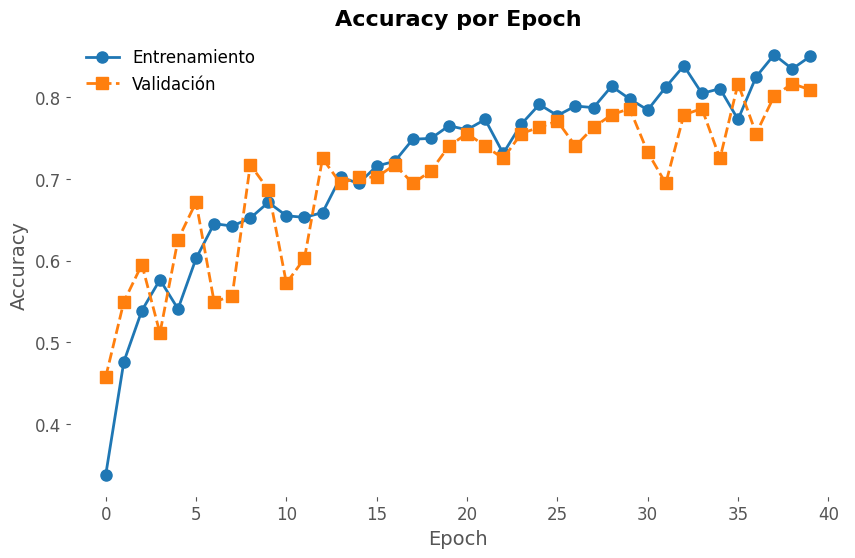

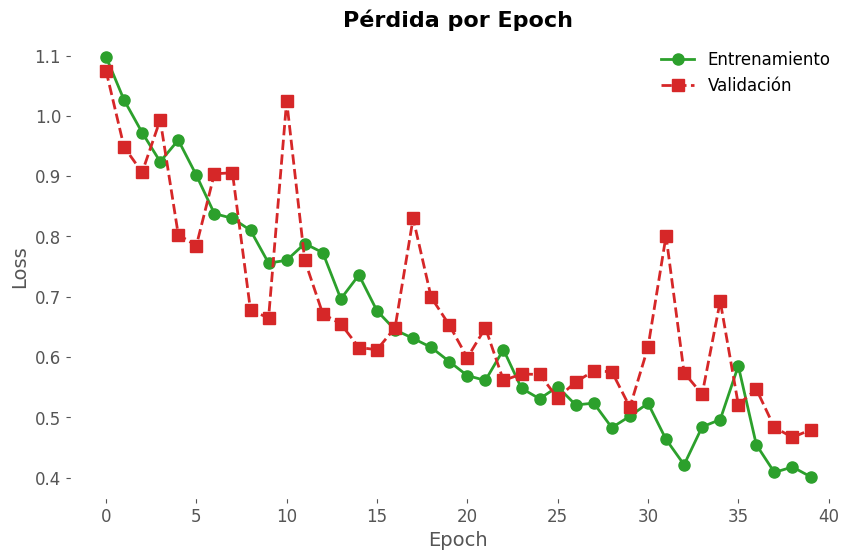

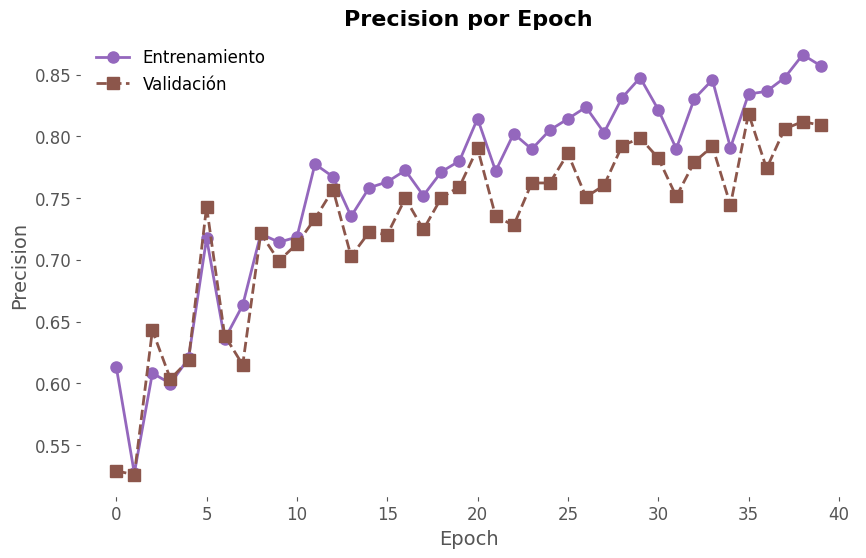

In [ ]:
plt.style.use('ggplot')
# Accuracy por epoch
plt.figure(figsize=(10,6))
plt.plot(history_cnn2dp.history['accuracy'], label='Entrenamiento', color=color_train, linewidth=linewidth, marker='o', markersize=markersize)
plt.plot(history_cnn2dp.history['val_accuracy'], label='Validación', color=color_val, linewidth=linewidth, linestyle='--', marker='s', markersize=markersize)
plt.title('Accuracy por Epoch', fontsize=16, weight='bold')
plt.xlabel('Epoch', fontsize=14)
plt.ylabel('Accuracy', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(fontsize=12, loc='best', frameon=False)
plt.grid(False)
plt.gca().set_facecolor('white')
plt.show()

# Pérdida por epoch
plt.figure(figsize=(10,6))
plt.plot(history_cnn2dp.history['loss'], label='Entrenamiento', color='#2ca02c', linewidth=linewidth, marker='o', markersize=markersize)
plt.plot(history_cnn2dp.history['val_loss'], label='Validación', color='#d62728', linewidth=linewidth, linestyle='--', marker='s', markersize=markersize)
plt.title('Pérdida por Epoch', fontsize=16, weight='bold')
plt.xlabel('Epoch', fontsize=14)
plt.ylabel('Loss', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(fontsize=12, loc='best', frameon=False)
plt.grid(False)
plt.gca().set_facecolor('white')
plt.show()

# Precision por epoch
plt.figure(figsize=(10,6))
plt.plot(precision_callbackcnn2dp.train_precisions, label='Entrenamiento', color='#9467bd', linewidth=linewidth, marker='o', markersize=markersize)
plt.plot(precision_callbackcnn2dp.val_precisions, label='Validación', color='#8c564b', linewidth=linewidth, linestyle='--', marker='s', markersize=markersize)
plt.title('Precision por Epoch', fontsize=16, weight='bold')
plt.xlabel('Epoch', fontsize=14)
plt.ylabel('Precision', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(fontsize=12, loc='best', frameon=False)
plt.grid(False)
plt.gca().set_facecolor('white')
plt.show()

**Métricas por clase para el del hiperparámetro optimizado**

In [ ]:
precision_accuracy_por_clase(modelo_cnn2dp, test_ds_pre)


Accuracy global: 0.7674
Precision macro global: 0.8218

--- Métricas por clase ---
Clase healthy: Accuracy = 0.5000 | Precision = 1.0000
Clase angular_leaf_spot: Accuracy = 0.9070 | Precision = 0.6393
Clase bean_rust: Accuracy = 0.9048 | Precision = 0.8261


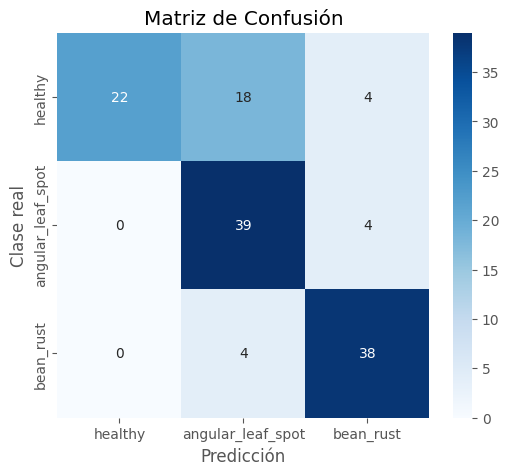

In [ ]:
plot_confusion_matrix(modelo_cnn2dp, test_ds_pre)

**Interpretabilidad**

  0%|          | 0/4998 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [00:58, 58.14s/it]               


<Figure size 500x500 with 0 Axes>

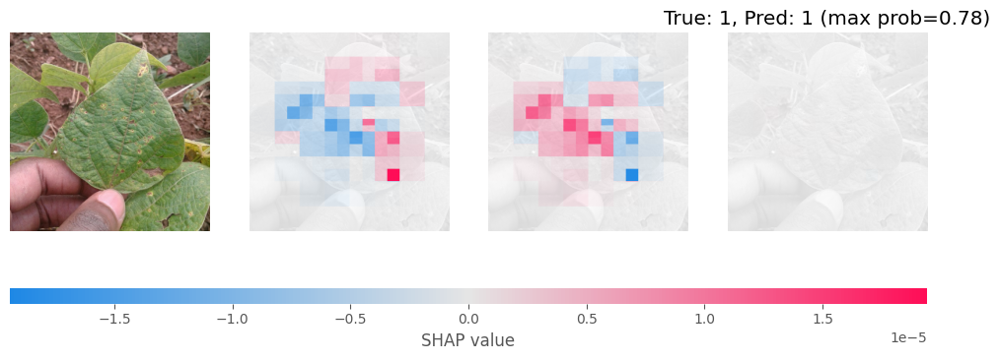

  0%|          | 0/4998 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [00:40, 40.80s/it]               


<Figure size 500x500 with 0 Axes>

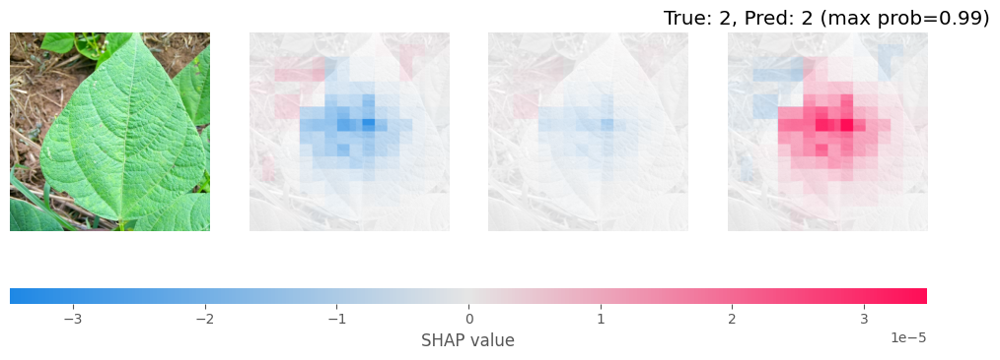

  0%|          | 0/4998 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [00:42, 42.28s/it]               


<Figure size 500x500 with 0 Axes>

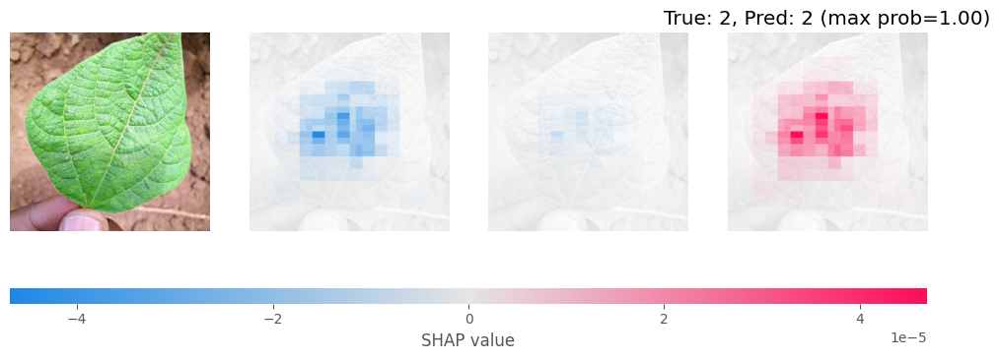

  0%|          | 0/4998 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [00:39, 39.97s/it]               


<Figure size 500x500 with 0 Axes>

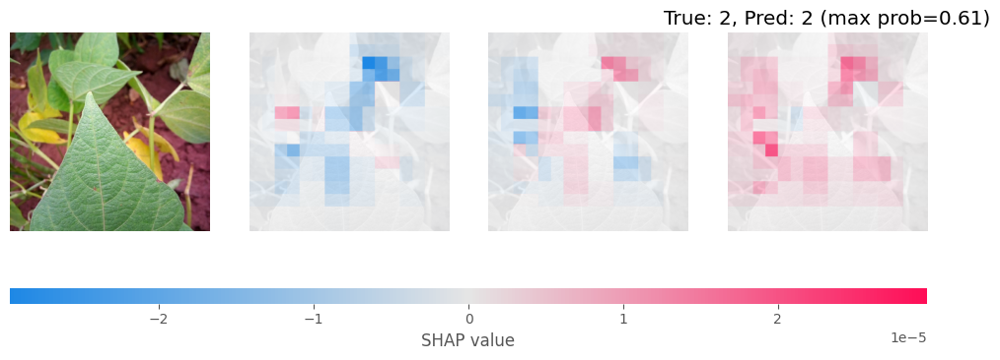

  0%|          | 0/4998 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [00:43, 43.59s/it]               


<Figure size 500x500 with 0 Axes>

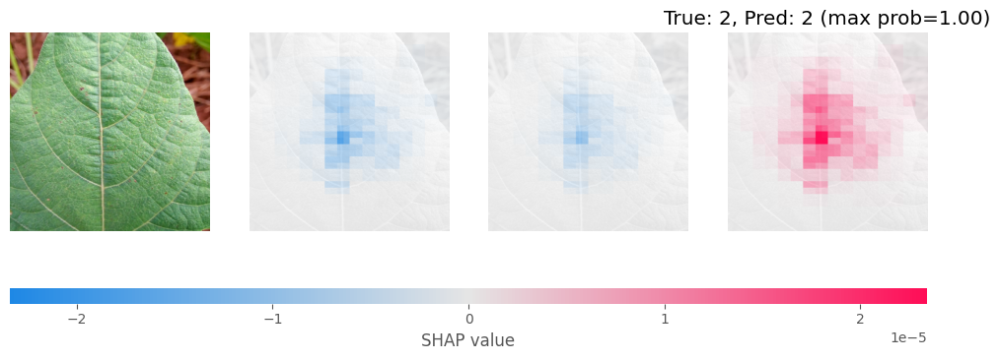

  0%|          | 0/4998 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [00:42, 42.34s/it]               


<Figure size 500x500 with 0 Axes>

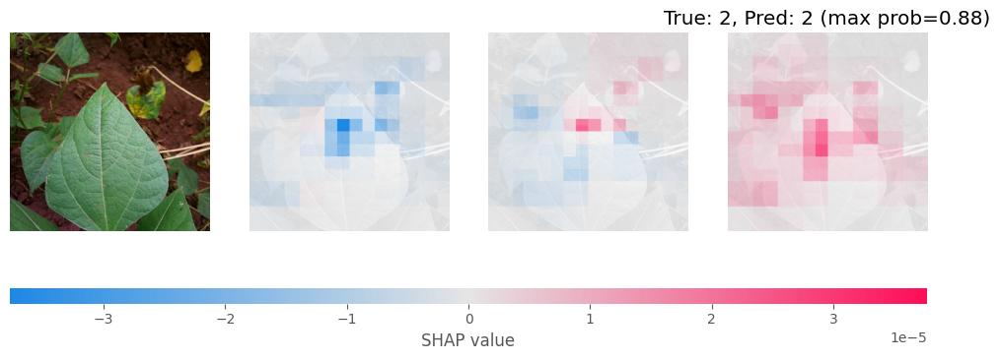

  0%|          | 0/4998 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [00:43, 43.62s/it]               


<Figure size 500x500 with 0 Axes>

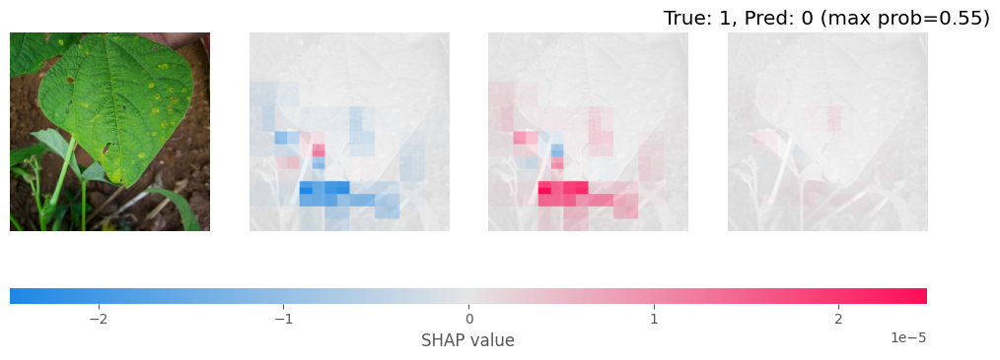

  0%|          | 0/4998 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [00:44, 44.41s/it]               


<Figure size 500x500 with 0 Axes>

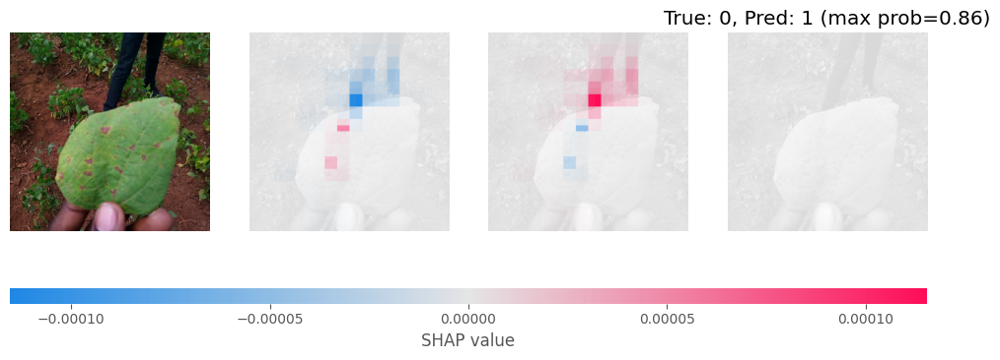

  0%|          | 0/4998 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [00:45, 45.92s/it]               


<Figure size 500x500 with 0 Axes>

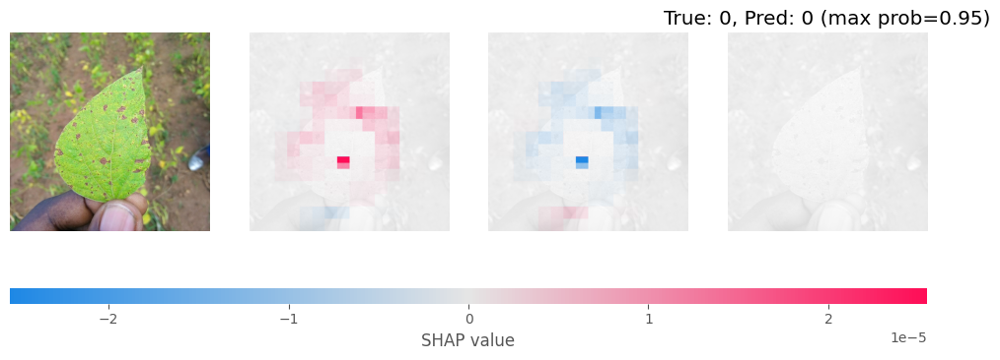

  0%|          | 0/4998 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [00:45, 45.35s/it]               


<Figure size 500x500 with 0 Axes>

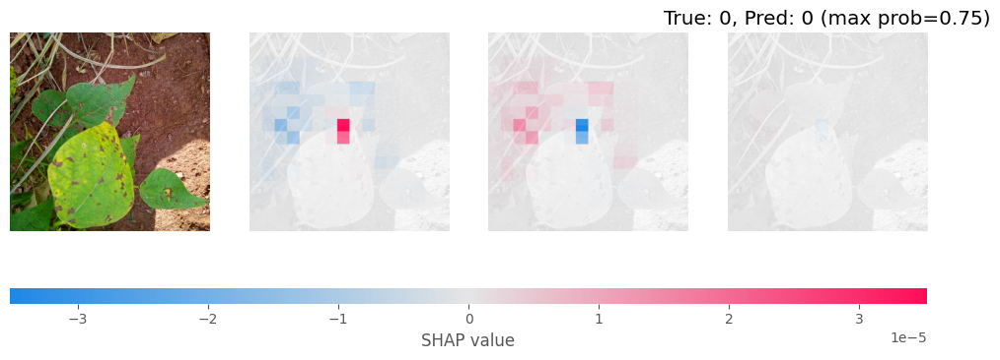

  0%|          | 0/4998 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [00:45, 45.70s/it]               


<Figure size 500x500 with 0 Axes>

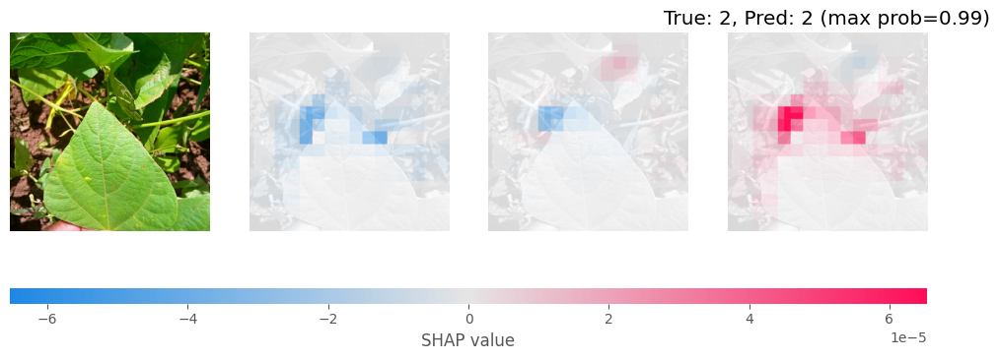

  0%|          | 0/4998 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [00:46, 46.20s/it]               


<Figure size 500x500 with 0 Axes>

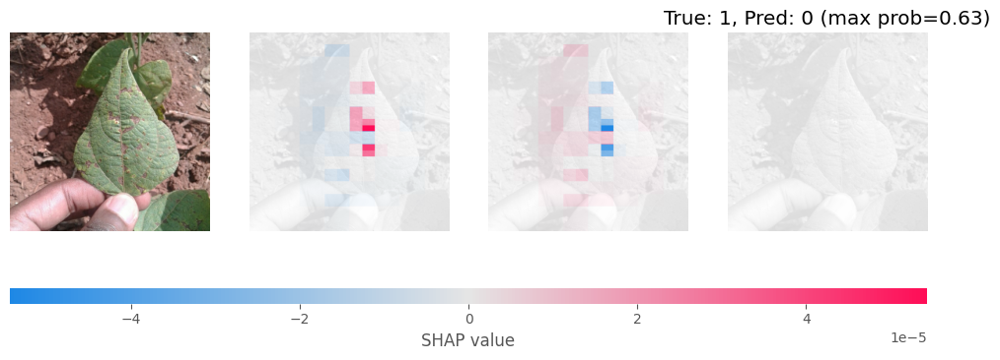

  0%|          | 0/4998 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [00:45, 45.43s/it]               


<Figure size 500x500 with 0 Axes>

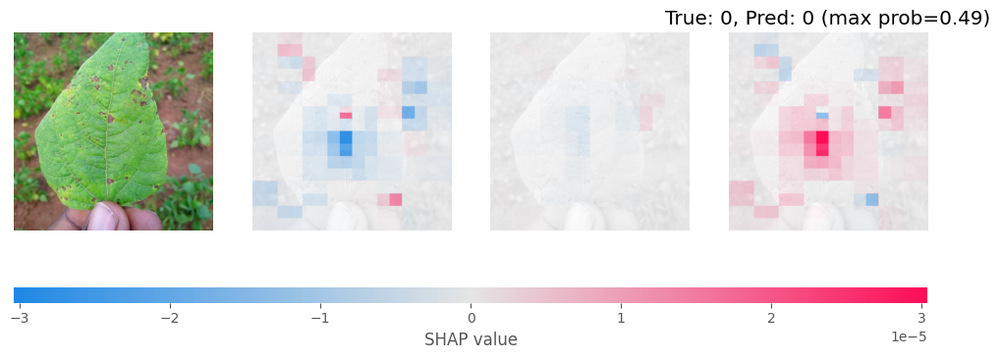

  0%|          | 0/4998 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [00:46, 46.39s/it]               


<Figure size 500x500 with 0 Axes>

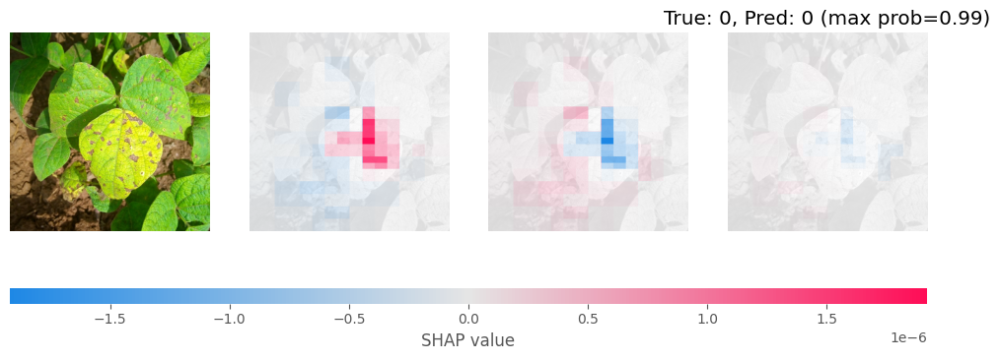

  0%|          | 0/4998 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [00:47, 47.72s/it]               


<Figure size 500x500 with 0 Axes>

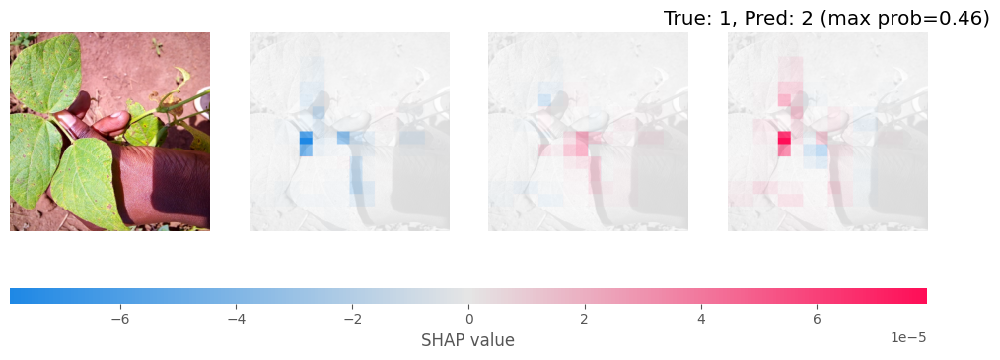

In [ ]:
import shap  # Importar SHAP

def f(x):
    # Ensure x is a NumPy array and properly normalized
    x = np.array(x, dtype=np.float32)
    if x.ndim == 3:  # single image
        x = np.expand_dims(x, axis=0)
    x_resized = tf.image.resize(x, (128,128)).numpy() / 255.0
    preds = modelo_cnn2dp.predict(x_resized, verbose=0)  # shape: (n_samples, 3)
    return preds

# --- Create SHAP masker for images ---
masker = shap.maskers.Image("blur(128,128)", X_test[0].shape)

# --- Create SHAP explainer ---
explainer = shap.Explainer(f, masker, output_names=nombres)

# --- Explain a few test samples ---
n_samples = 15
for ind in range(n_samples):
    sample = X_test[[ind]]
    shap_values = explainer(sample, max_evals=5000, batch_size=50)

    # --- Visualize SHAP values for all 3 classes ---
    shap_list = [shap_values.values[..., :, :, c] for c in range(shap_values.values.shape[-1])]
    plt.figure(figsize=(5,5))
    shap.image_plot(shap_list, sample, show=False)

    # --- Display prediction ---
    pred_probs = modelo_cnn2dp.predict(tf.image.resize(sample, (128,128))/255.0, verbose=0)[0]
    true_class = y_test[ind]
    pred_class = np.argmax(pred_probs)
    plt.title(f"True: {true_class}, Pred: {pred_class} (max prob={np.max(pred_probs):.2f})")
    plt.show()